In [1]:
%load_ext autoreload
%autoreload 2

import sys, copy, os
from pathlib import Path
import numpy as np

root_dir = Path.cwd().parent
if not root_dir in sys.path:
    sys.path.insert(0, str(root_dir))
from matplotlib import pyplot as plt

# from run_detection import run_detection
import caiman
from caiman.source_extraction import cnmf as cnmf
from caiman.motion_correction import MotionCorrect

from neuron_detection import motion_correct, neuron_detection, CaImAn_params, make_tif_stack
# from image_processing.motion_correct import motion_correct, plot_results_motion_correction
# from image_processing.neuron_detection import neuron_detection
# from utils.parameters import CaImAn as CaImAn_params, params_motion

os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"

In [2]:
# root_dir = Path.cwd().parents[2]
# if not root_dir in sys.path:
#     sys.path.insert(0, str(root_dir))
print("Root dir:", root_dir)

Root dir: /home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman


In [3]:
prefix = "results_CaImAn"
suffix = ""
save_type = "hdf5"  # "mat" or "hdf5"
n_processes = 12

# tmp_dir = Path("/home/wollex/caiman_data/temp")
# session_path = Path("../../../../data/Subhodeep/ID45/20230912/")
session_path = Path("../../../../data/KotaroData/493/Session02")

In [4]:
fname = [file for file in session_path.iterdir() if file.suffix == ".tif"][0]
print("Processing file:", fname)
# path_to_motion_correct = [file for file in tmp_dir.iterdir() if file.suffix == ".mmap"][
#     0
# ]

resultFile_name = f"{prefix}_{Path(fname).stem}{suffix}"
result_path = session_path / f"{resultFile_name}.{save_type}"
use_parallel = n_processes is not None and n_processes > 1

print(result_path)

Processing file: ../../../../data/KotaroData/493/Session02/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t.tif
../../../../data/KotaroData/493/Session02/results_CaImAn_df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t.hdf5


path tmp: ../../../../data/KotaroData/493/Session05/tmp
copying  df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t.tif  to  ../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t.tif


In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


finally, saving file to results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t
using parameters:
  fr: 15.0
  decay_time: 0.47
  dxy: 0.9647998794000152
  rf: 48
  stride: 8
  border_pix: 0
  nb: 2
  gSig: [10, 10]
  gSiz: (21, 21)
  min_SNR: 2.5
  SNR_lowest: 1.0
  rval_thr: 0.8
  rval_lowest: -1
  min_cnn_thr: 0.9
  cnn_lowest: 0.1
  use_cnn: True
  motion_correct: False
  epochs: 1
  normalize: True
  init_batch: 1000
  init_method: cnmf
  dist_shape_update: True
  update_freq: 1000
  use_dense: False
  merge_thr: 0.65
  max_shifts: (6, 6)
  strides: (48, 48)
  overlaps: (24, 24)
  max_deviation_rigid: 3
  pw_rigid: True
  show_movie: False
  save_online_movie: False
	Now running motion correction @t = Wed Jan  7 13:19:52 2026


100%|██████████| 1/1 [00:41<00:00, 41.02s/it]


	Motion correction done @t = Wed Jan  7 13:30:52 2026, (time passed: 660.2150859832764)
path to motion_correct: ../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
in the end, saving results to: ../../../../data/KotaroData/493/Session05/results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t.hdf5
	Now running neuron detection @t = Wed Jan  7 13:30:52 2026


In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)
No file saved


FileNotFoundError: [Errno 2] No such file or directory: '../../../../data/KotaroData/493/Session05/tmp/../../../../data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C'

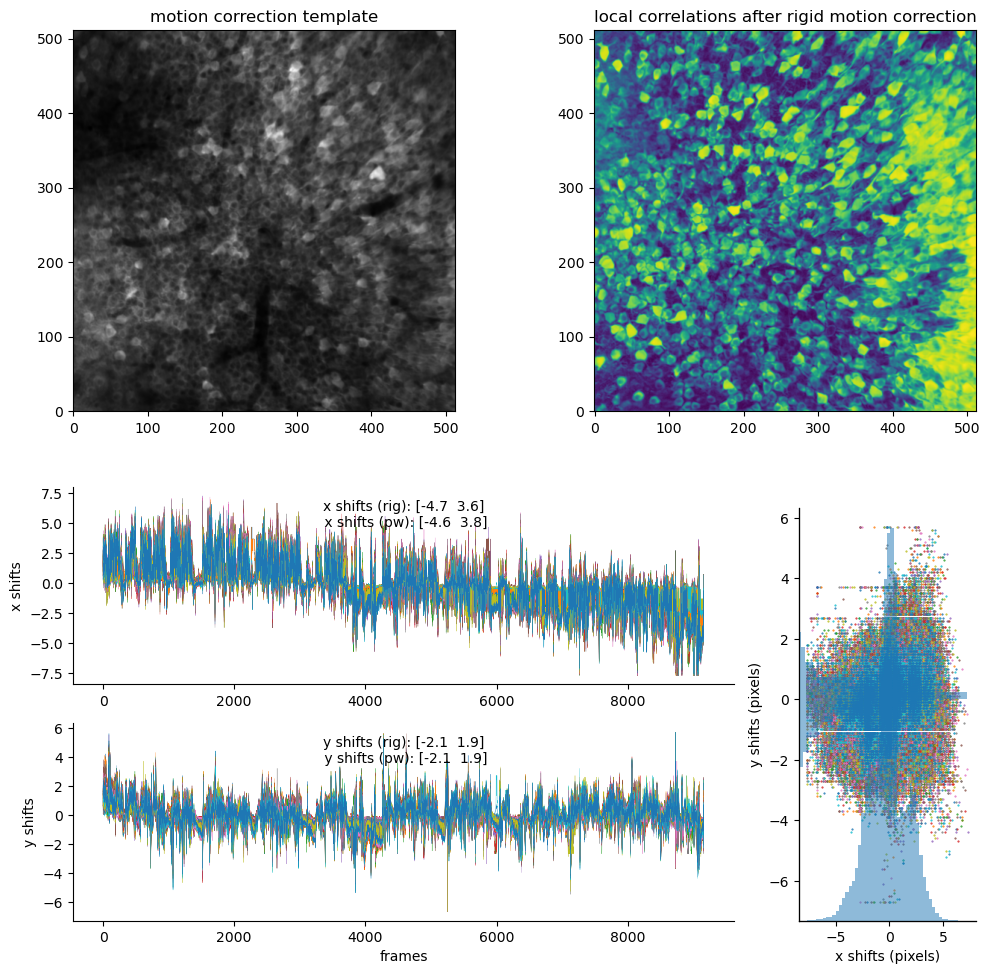

In [5]:
from turnover_dynamics.neuron_detection_caiman.neuron_detection.run_detection import (
    run_detection,
)

# run_detection(source=fname, additional_params={"fr": 30.05, "decay_time": 1.5})
run_detection(source=fname, fr=15.0, decay_time=0.47)

in the end, saving results to: ../../../../data/KotaroData/493/Session05/results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t.hdf5
	Now running neuron detection @t = Wed Jan  7 14:49:08 2026
../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap


In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/init_file.hdf5


No file saved


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/init_file.hdf5
Yr_d1_512_d2_512_d3_1_order_C
not force
base: Yr
tot: /home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C
tot2: /home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C_frames_1000.mmap
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C_frames_1000.mmap
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/Yr_d1_512_d2_512_d3_1_order_C_frames_1000.mmap
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/

...

/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap


Component 6 is almost empty. Space correlation is set to 0.


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


NaN values detected for space correlation in [ 214  458  657  709  832 1087 1139]. Changing their value to -1.


Evaluated components
Num accepted/rejected: 336, 855
Plotting quality for 336 good and 855 bad neurons
Saving results to ../../../../data/KotaroData/493/Session05/results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t.hdf5
../../../../data/KotaroData/493/Session05/results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t.hdf5
	Neuron detection done @t = Wed Jan  7 16:18:08 2026, (time passed: 5340.04296875)


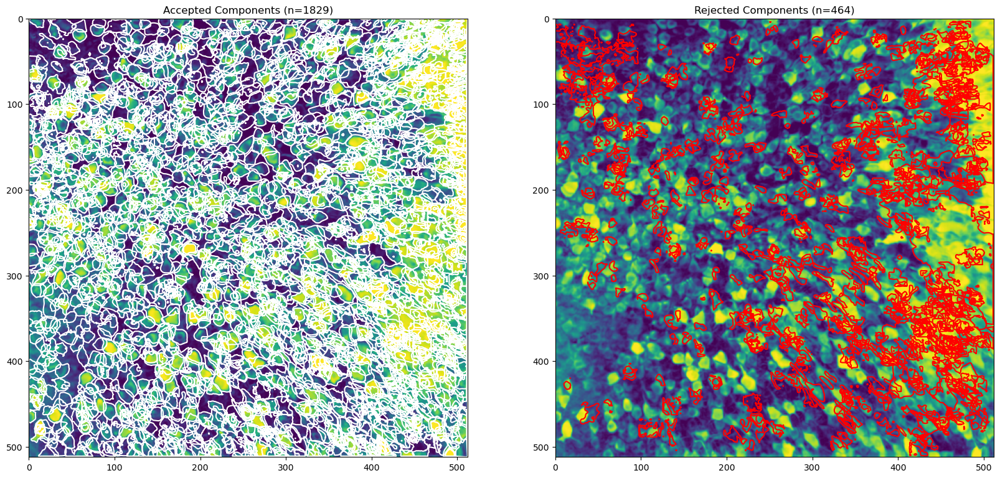

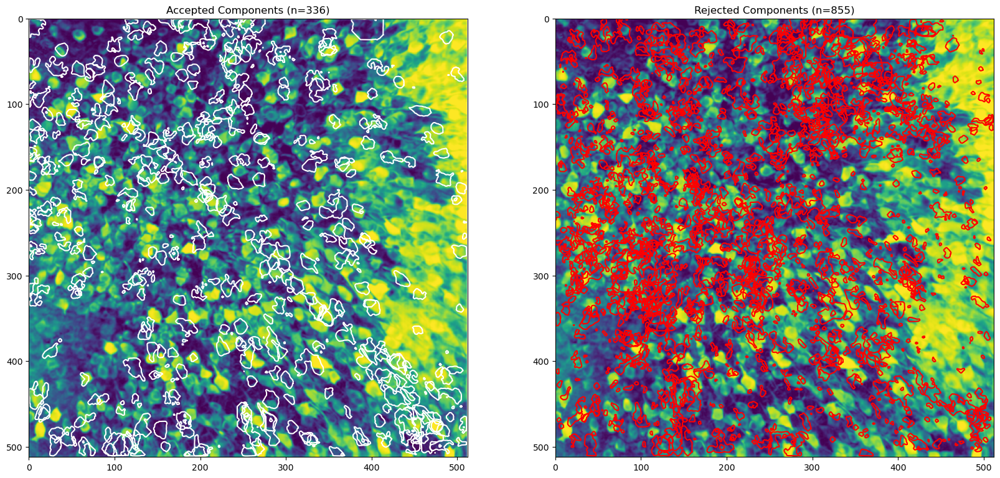

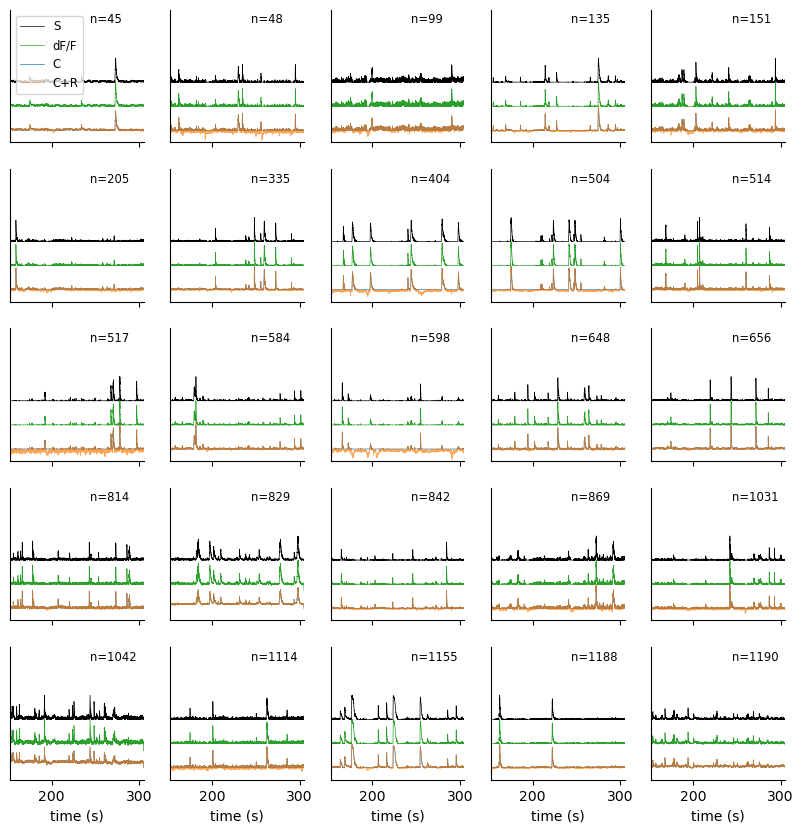

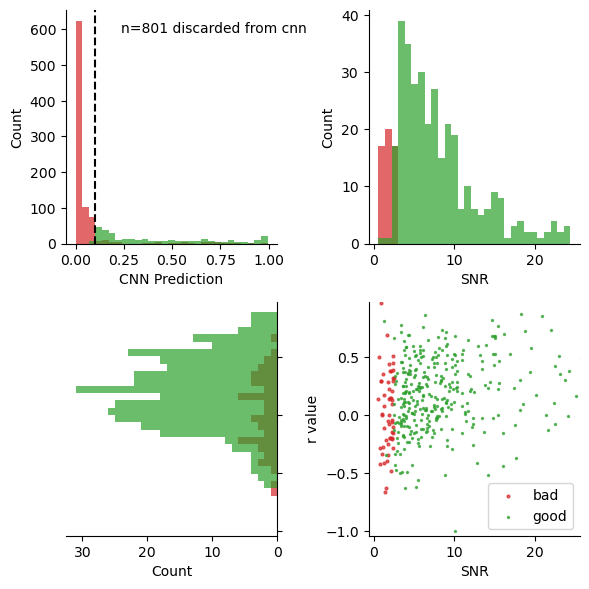

In [44]:
path_to_motion_correct = "../../../../data/KotaroData/493/Session05/tmp/df1cko#493_m2_hp_x16_x1.5_15v_99um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap"
params = copy.deepcopy(CaImAn_params)

path_to_neuron_detection = neuron_detection(
    path_to_motion_correct,
    params,
    path_destination=session_path,
    fname_stem=fname.stem,
    n_processes=1,
    plot=True,
)

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


	Now running motion correction @t = Mon Jan 12 12:56:23 2026


Default temporary dir /home/wollex/caiman_data/temp does not exist, creating
100%|██████████| 1/1 [00:02<00:00,  2.90s/it]


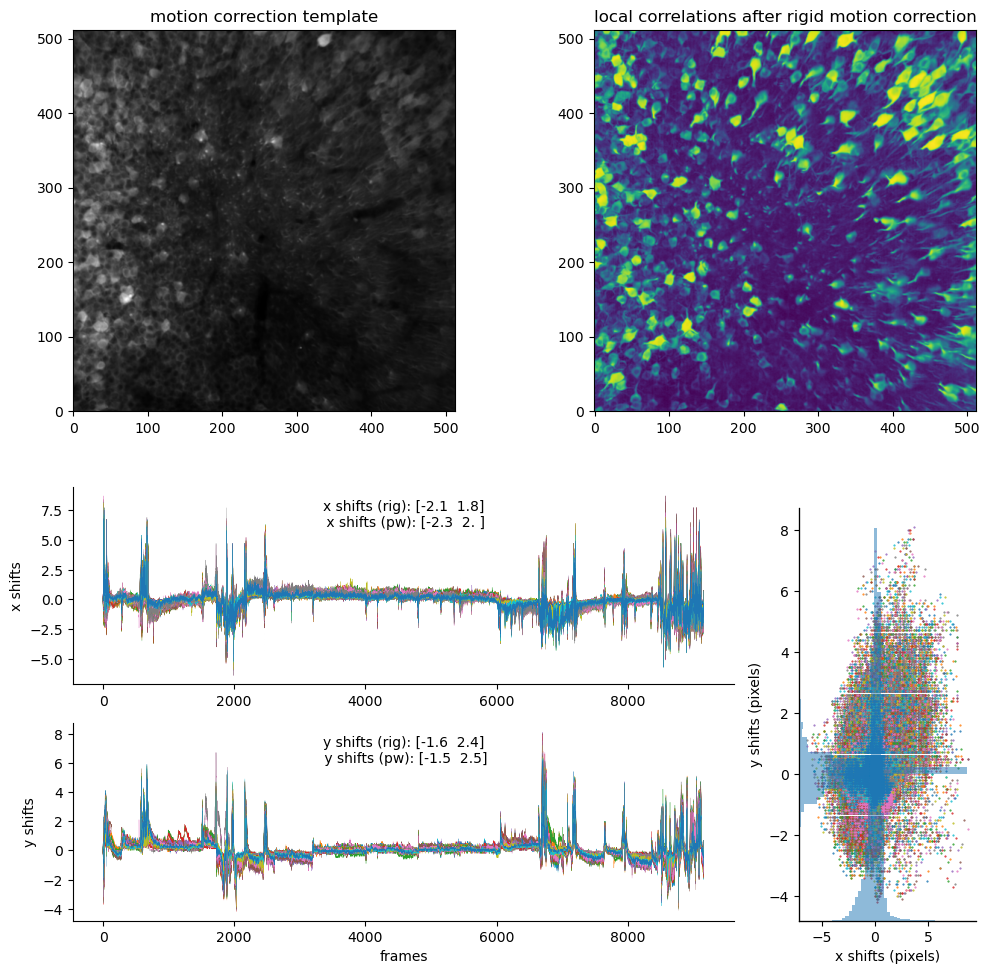

	Motion correction done @t = Mon Jan 12 13:01:41 2026, (time passed: 317.94921493530273)


In [18]:
# params = copy.deepcopy(params_motion)
# params["fr"] = 30.05
# params.update(additional_params)

if "dview" in locals():  # 'locals' contains list of current local variables
    caiman.stop_server(dview=dview)
path_to_motion_correct = motion_correct(
    fname,
    params=params,
    n_processes=n_processes,
    path_destination=session_path,
    plot=True,
)

In [ ]:
path_tmp = Path.home() / "caiman_data" / "temp"
path_to_motion_correct = str(
    [file for file in path_tmp.iterdir() if file.suffix == ".mmap"][0]
)
path_to_motion_correct

'/home/wollex/caiman_data/temp/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap'

In [11]:
cnmf_batch = cnmf.cnmf.load_CNMF(str(result_path))

params = copy.deepcopy(CaImAn_params)
params["fr"] = 15.0
params["decay_time"] = 0.47  # GCaMP6f[1]

params["fnames"] = [path_to_motion_correct]
params["p"] = 2
params["epochs"] = 1
params["show_movie"] = False  # whether to display movie while fitting
params["n_processes"] = n_processes
params["init_method"] = "cnmf"

opts = cnmf.params.CNMFParams(params_dict=params)

# opts.set("temporal", {"p": 2, "optimize_g": True})
cnmf_batch.params = opts

Datafile ../../../../data/KotaroData/493/Session02/results_CaImAn_df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t.hdf5 not marked as cnmf
In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


In [13]:
if use_parallel:
    if "dview" in locals():
        caiman.stop_server(dview=dview)
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
images = np.reshape(Yr.T, [num_frames] + list(dims), order="C")
cnmf_batch.mmap_file = str(path_to_motion_correct)
cnmf_batch = cnmf_batch.refit(images, dview)

In [14]:
f = 15.0
if "dview" in locals():  # 'locals' contains list of current local variables
    caiman.stop_server(dview=dview)
if use_parallel:
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_batch.estimates.detrend_df_f(
    quantileMin=8, frames_window=int(10 * f), flag_auto=False, use_residuals=False
)
print("Detrended df/f")

cnmf_batch.estimates.deconvolve(cnmf_batch.params, dview=dview, dff_flag=False)
cnmf_batch.estimates.deconvolve(cnmf_batch.params, dview=dview, dff_flag=True)
# Yr, dims, num_frames = caiman.load_memmap(str(fname))

setattr(cnmf_batch.estimates, "dview", dview)
cnmf_batch.estimates.compute_residuals(Yr)

images = np.reshape(Yr.T, [num_frames] + list(dims), order="F")
del Yr
print("Computed residuals")

cnmf_batch.estimates.evaluate_components(images, cnmf_batch.params, dview=dview)
print("Evaluated components")
del images

print(
    f"Num accepted/rejected: {len(cnmf_batch.estimates.idx_components)}, {len(cnmf_batch.estimates.idx_components_bad)}"  # type: ignore
)

Detrended df/f
Computed residuals
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Evaluated components
Num accepted/rejected: 711, 103


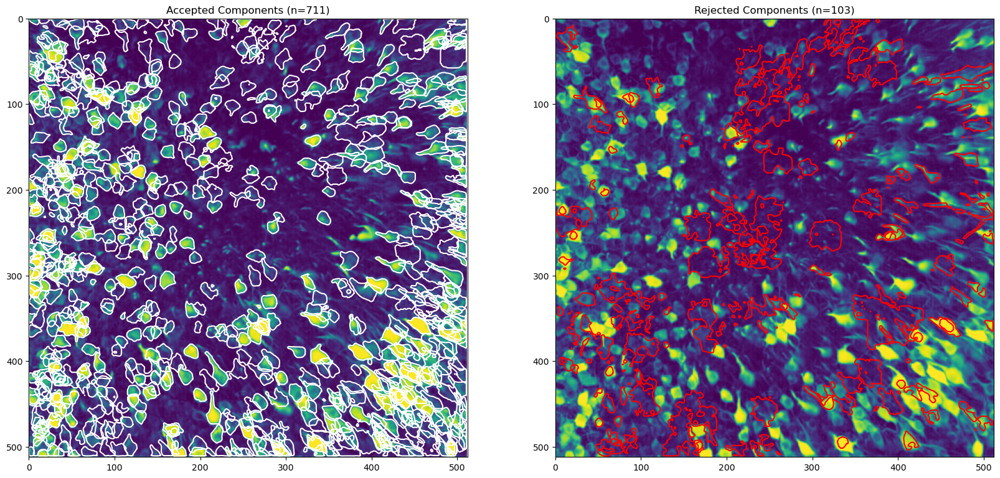

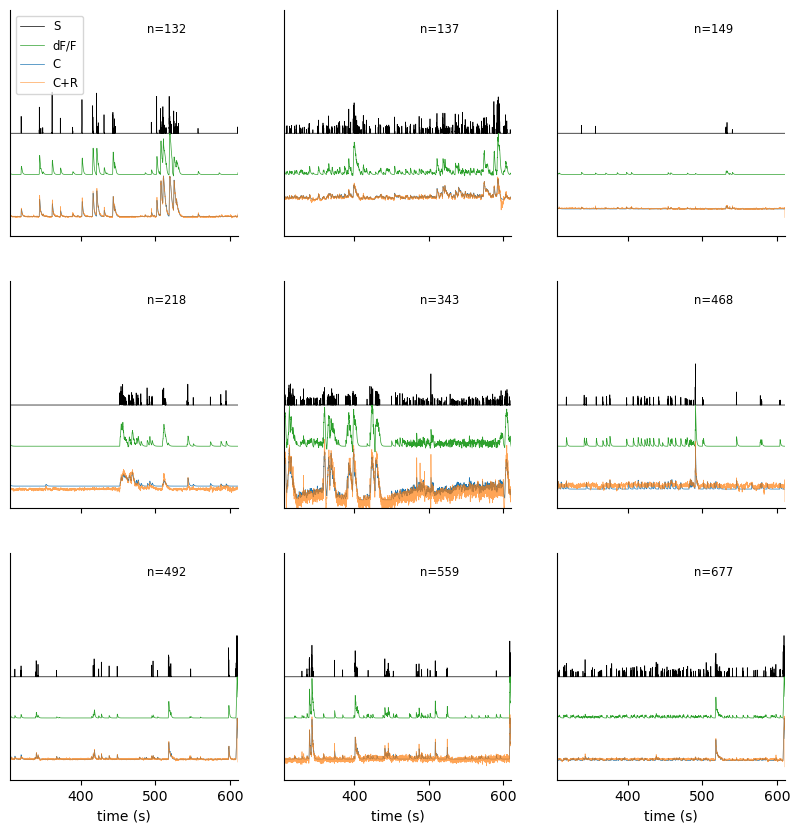

Plotting quality for 711 good and 103 bad neurons


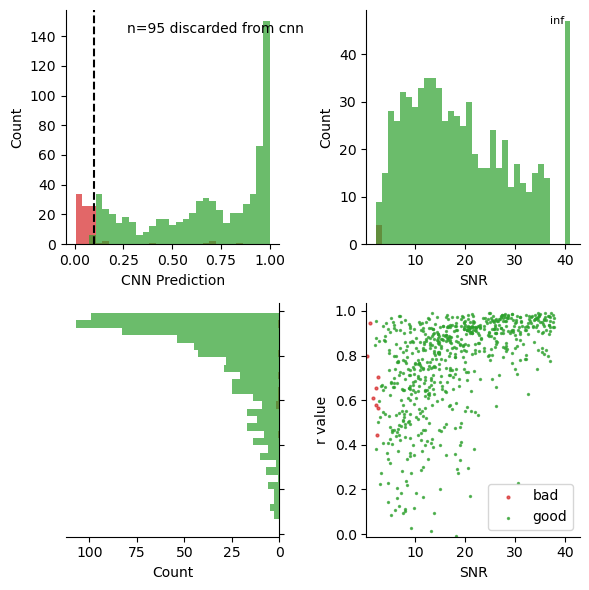

In [19]:
from neuron_detection.image_processing.neuron_detection import (
    plot_contours,
    plot_traces,
    plot_quality,
)

# %matplotlib ipympl
plot_contours(
    cnmf_batch.estimates,
)
plot_traces(
    cnmf_batch.estimates,
    f=f,
    n_plots=(3, 3),
)
plot_quality(cnmf_batch)

In [ ]:
from utils.display_videos import display_videos

display_videos([path_to_motion_correct], f=30.05)

[[0.13831103 0.13288166 0.14135875 ... 0.13964805 0.13964805 0.13464805]
 [0.13318537 0.14022379 0.1358842  ... 0.14114806 0.13514806 0.14064805]
 [0.13220719 0.131607   0.12625705 ... 0.13914806 0.13314806 0.14164805]
 ...
 [0.1370851  0.12827832 0.16844437 ... 0.13632073 0.13625398 0.13699688]
 [0.1337127  0.14023827 0.14218858 ... 0.25239417 0.13443886 0.13859703]
 [0.13660596 0.14242297 0.1307205  ... 0.14820518 0.13320962 0.1377335 ]]
[[0.13831103 0.13288166 0.14135875 ... 0.13964805 0.13964805 0.13464805]
 [0.13318537 0.14022379 0.1358842  ... 0.14114806 0.13514806 0.14064805]
 [0.13220719 0.131607   0.12625705 ... 0.13914806 0.13314806 0.14164805]
 ...
 [0.1370851  0.12827832 0.16844437 ... 0.13632073 0.13625398 0.13699688]
 [0.1337127  0.14023827 0.14218858 ... 0.25239417 0.13443886 0.13859703]
 [0.13660596 0.14242297 0.1307205  ... 0.14820518 0.13320962 0.1377335 ]]
[[0.14235857 0.13277252 0.16615503 ... 0.14697254 0.14647253 0.14597254]
 [0.14622383 0.13677703 0.13500889 ... 

KeyboardInterrupt: 

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


in the end, saving results to: ../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00006.hdf5
	Now running neuron detection @t = Sat Jan  3 14:51:24 2026


No file saved
Now processing file /home/wollex/caiman_data/temp/20230912_45_00006_els__d1_512_d2_512_d3_1_order_F_frames_24503.mmap
Component 5 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 10 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 22 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 25 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 34 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 33 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 33 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 35 is only active jointly with neighboring comp

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 624us/step
Evaluated components
*** Variable R has not the same number of components as A ***
*** Variable g has not the same number of components as A ***
*** Variable c1 has not the same number of components as A ***
*** Variable neurons_sn has not the same number of components as A ***
*** Variable lam has not the same number of components as A ***


Datafile ../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00006.hdf5 not marked as cnmf


Detrended df/f
Computed residuals
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step 
Evaluated components
Num accepted/rejected: 70, 80
Plotting quality for 70 good and 80 bad neurons


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:655: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saving results to ../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00006_final.hdf5
	Neuron detection done @t = Sat Jan  3 16:01:05 2026, (time passed: 4181.027848482132)


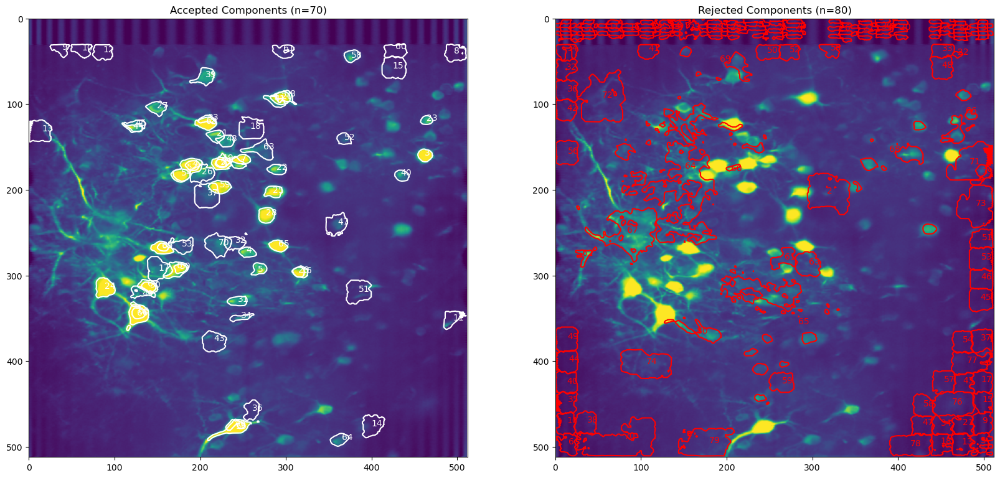

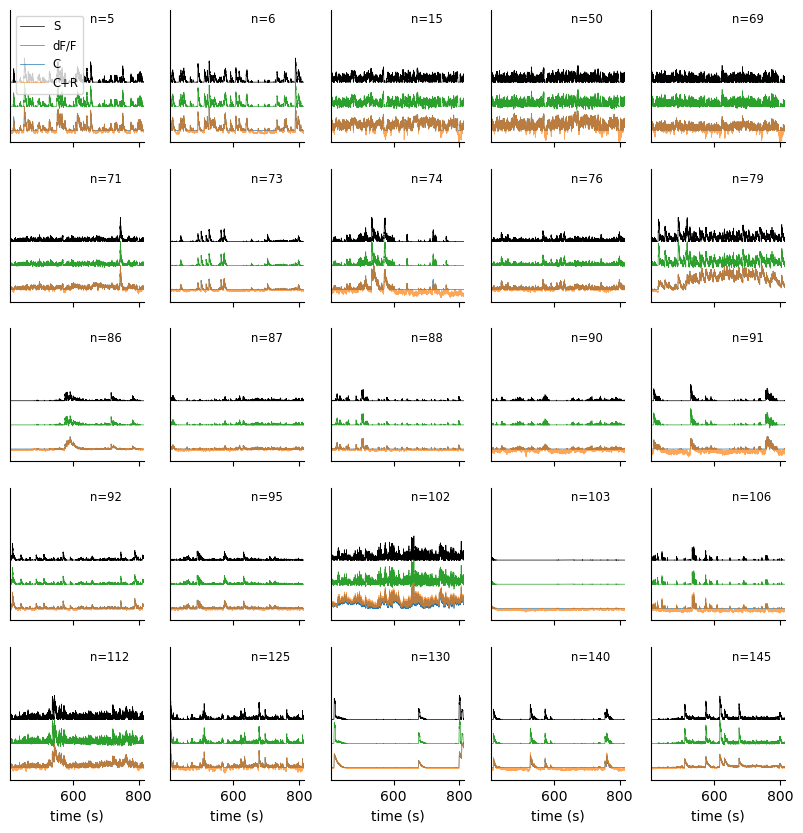

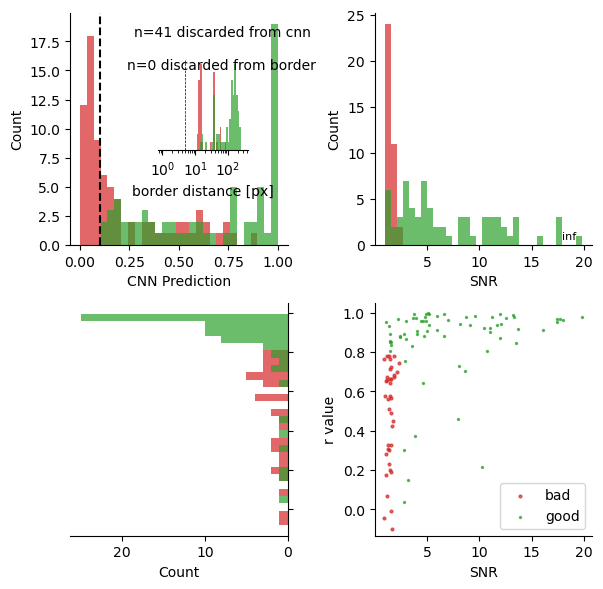

In [5]:
params = copy.deepcopy(CaImAn_params)

path_to_neuron_detection = neuron_detection(
    path_to_motion_correct,
    params,
    save_name=resultFile_name,
    n_processes=n_processes,
    save_type=save_type,
    plot=True,
    path_destination=session_path,
)

In [10]:
import numpy as np


def post_processing(cnmf_obj: cnmf.cnmf.CNMF, path_to_motion_correct, dview=None):

    ## costly evaluations
    f = cnmf_obj.params.get("data", "fr")

    cnmf_obj.estimates.detrend_df_f(
        quantileMin=8, frames_window=int(10 * f), flag_auto=False, use_residuals=False
    )
    print("Detrended df/f")

    m_rig = caiman.load(str(path_to_motion_correct))
    Cn = caiman.local_correlations(m_rig, swap_dim=False)
    cnmf_obj.estimates.Cn = Cn
    del m_rig

    cnmf_obj.estimates.deconvolve(cnmf_obj.params, dview=dview, dff_flag=False)
    cnmf_obj.estimates.deconvolve(cnmf_obj.params, dview=dview, dff_flag=True)

    Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
    images = np.reshape(Yr.T, [num_frames] + list(dims), order="F")

    cnmf_obj.estimates.dview = dview
    cnmf_obj.estimates.compute_residuals(Yr)
    del Yr
    print("Computed residuals")

    cnmf_obj.estimates.evaluate_components(images, cnmf_obj.params, dview=dview)
    print("Evaluated components")
    del images

    print(
        f"Num accepted/rejected: {len(cnmf_obj.estimates.idx_components)}, {len(cnmf_obj.estimates.idx_components_bad)}"
    )

    return cnmf_obj

Detrended df/f
Computed residuals


Component 26 is only active jointly with neighboring components. Space correlation calculation might be unreliable.


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Evaluated components
Num accepted/rejected: 277, 0
Plotting quality for 277 good and 0 bad neurons


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:655: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


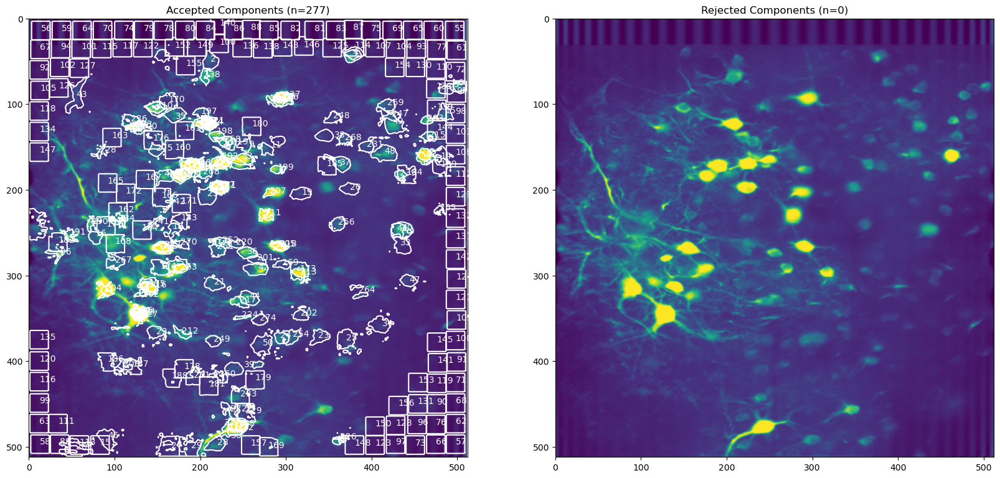

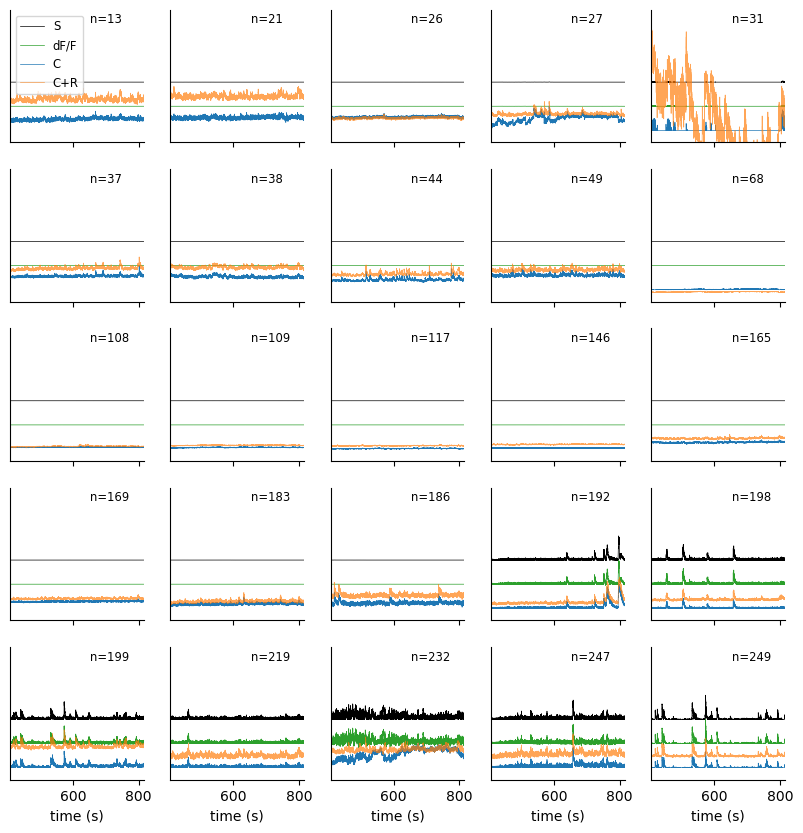

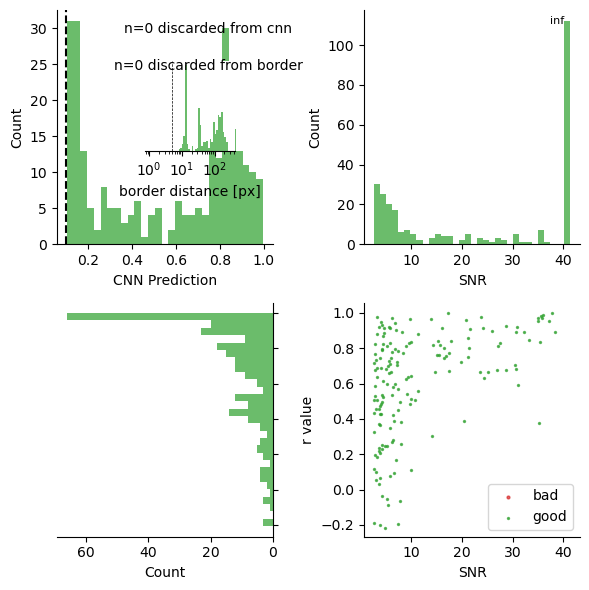

In [ ]:
fname = "../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00006.hdf5"
# cnmf_batch = cnmf.cnmf.load_CNMF(str(fname))

from image_processing.neuron_detection import plot_contours, plot_traces, plot_quality

if use_parallel:
    if "dview" in locals():  # 'locals' contains list of current local variables
        # print("Closing previous cluster")
        caiman.stop_server(dview=dview)
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1
cnmf_batch = post_processing(cnmf_batch, path_to_motion_correct, dview=dview)
plot_contours(cnmf_batch.estimates, display_numbers=True)
plot_traces(cnmf_batch.estimates, f=30.05, n_plots=(5, 5))
plot_quality(cnmf_batch)

In [ ]:
# fname = path_to_motion_correct
params = copy.deepcopy(CaImAn_params)


# resultFile_name = f"{prefix}_{Path(fname).stem}{suffix}"
if "dview" in locals():  # 'locals' contains list of current local variables
    caiman.stop_server(dview=dview)

save_name = resultFile_name

params["fnames"] = [path_to_motion_correct]
params["p"] = 0
params["epochs"] = 1
params["show_movie"] = False  # whether to display movie while fitting
params["n_processes"] = n_processes
params["init_method"] = "cnmf"
# params["optimize_g"] = False  #
# params["sniper_mode"] = False  # otherwise, returns progress bar on every step....
# params["stop_detection"] = True  # don't detect new neurons in last epoch

opts = cnmf.params.CNMFParams(params_dict=params)
if use_parallel:
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

# try:
cnmf_obj = cnmf.online_cnmf.OnACID(params=opts, dview=dview)
cnmf_obj.fit_online()

Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
images = np.reshape(Yr.T, [num_frames] + list(dims), order="F")
cnmf_obj.estimates.evaluate_components(images, cnmf_obj.params, dview=dview)
cnmf_obj.estimates.select_components(use_object=True, save_discarded_components=False)
# cnmf_obj = post_processing(cnmf_obj, path_to_motion_correct, dview=dview)
cnmf_obj.save(str(result_path))

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)
No file saved
Now processing file /home/wollex/caiman_data/temp/20230912_45_00004_els__d1_512_d2_512_d3_1_order_F_frames_24514.mmap
/home/wollex/miniforge3/envs/caiman/lib/python3.11/site-packages/caiman/components_evaluation.py:112: RuntimeWarning: invalid value encountered in divide
  sd_r = np.sqrt(np.sum(ff1**2, 1) / Ns)


Detrended df/f
Computed residuals


Component 20 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 23 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 21 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 25 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 30 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 31 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 32 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 39 is only active jointly with neighboring components. Space correlation calculation might be unreliable.
Component 35 is only active jointly with neighboring components. Space c

33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Evaluated components
Num accepted/rejected: 305, 727


In [16]:
from turnover_dynamics.neuron_detection_caiman.image_processing.neuron_detection import (
    clear_cnm,
)
from image_processing.neuron_detection import plot_contours, plot_quality, plot_traces

cnmf_batch = cnmf.cnmf.load_CNMF(str(fname))
# cnmf_batch.estimates.select_components(use_object=True, save_discarded_components=False)

# Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
# images = np.reshape(Yr.T, [num_frames] + list(dims), order="F")
# cnmf_batch.estimates.evaluate_components(images, cnmf_batch.params, dview=dview)
# plot_contours(cnmf_batch.estimates, display_numbers=True)
# plot_traces(cnmf_batch.estimates, f=30.05, n_plots=(5, 5))
# plot_quality(cnmf_batch)

Datafile ../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00006.hdf5 not marked as cnmf


In [14]:
cnmf_batch.estimates.dview = None

Detrended df/f
Computed residuals
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step  
Evaluated components
Num accepted/rejected: 70, 80
Plotting quality for 70 good and 80 bad neurons


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:655: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


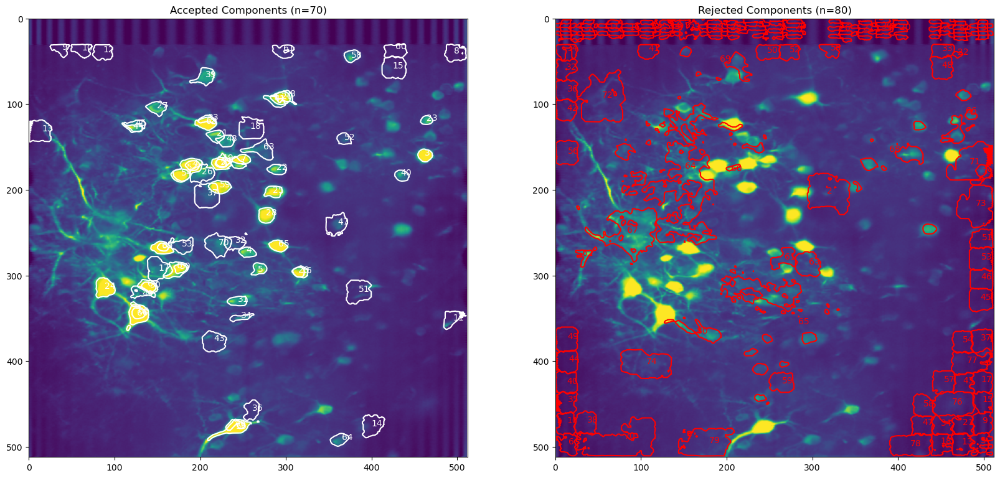

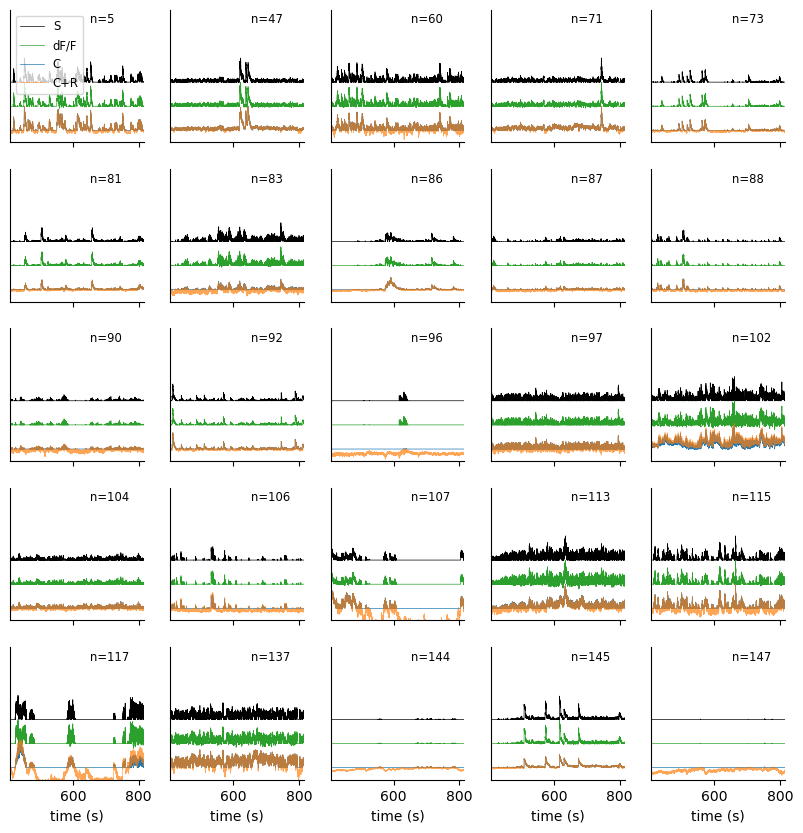

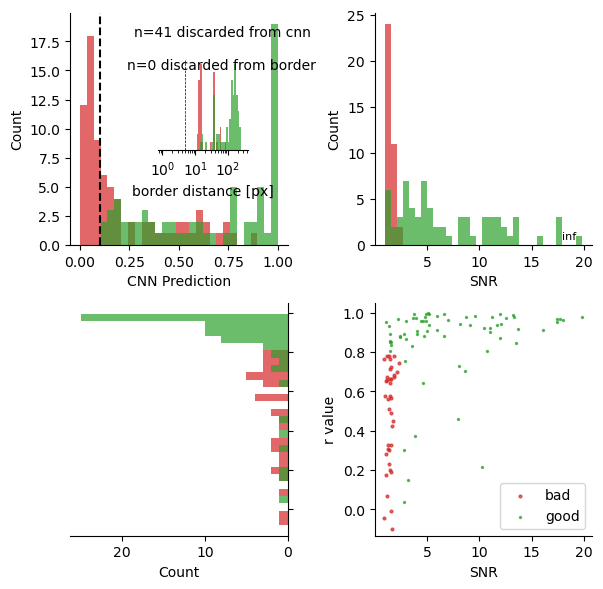

In [17]:
if use_parallel:
    if "dview" in locals():  # 'locals' contains list of current local variables
        # print("Closing previous cluster")
        caiman.stop_server(dview=dview)
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_batch.params.set("temporal", {"p": 2, "optimize_g": True})
Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
images = np.reshape(Yr.T, [num_frames] + list(dims), order="C")
cnmf_batch.mmap_file = path_to_motion_correct
cnmf_batch = cnmf_batch.refit(images, dview)

cnmf_batch = post_processing(cnmf_batch, path_to_motion_correct, dview=dview)

plot_contours(cnmf_batch.estimates, display_numbers=True)
plot_traces(cnmf_batch.estimates, f=30.05, n_plots=(5, 5))
plot_quality(cnmf_batch)

# # cnmf_batch.deconvolve(optimize_g=True)
# cnmf_batch.estimates.select_components(use_object=True, save_discarded_components=False)

# retain_keys = [
#     "A",
#     "C",
#     "S",
#     "S_dff",
#     "F_dff",
#     "F_dff_dec",
#     "b",
#     "f",
#     "R",
#     "Cn",
#     "dims",
#     "coordinates",  # need this?
#     "center",
#     "SNR_comp",
#     "r_values",
#     "cnn_preds",
#     "sn",
#     "bl",
#     "c1",
#     "neurons_sn",
#     "g",
#     "YrA",
# ]

# cnmf_batch.estimates = clear_cnm(cnmf_batch.estimates, retain=retain_keys)

# result_path_final = session_path / f"{resultFile_name}_final.{save_type}"
# cnmf_batch.save(str(result_path_final))

In [127]:
# plot_contours(cnmf_batch.estimates, display_numbers=True)
# cnmf_batch.estimates.idx_components = None
# cnmf_batch.estimates.idx_components_bad = None
cnmf_batch = post_processing(cnmf_batch, path_to_motion_correct, dview=dview)
# plot_traces(cnmf_batch.estimates, f=30.05, n_plots=(5, 5))
# plot_quality(cnmf_batch)

Detrended df/f
Computed residuals
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
Evaluated components
Num accepted/rejected: 73, 0


Plotting quality for 73 good and 0 bad neurons


<string>:50: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


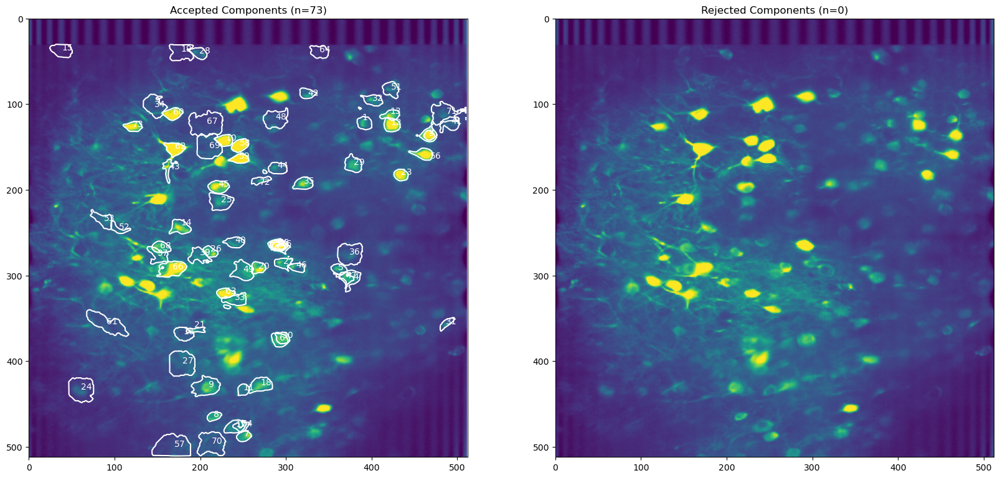

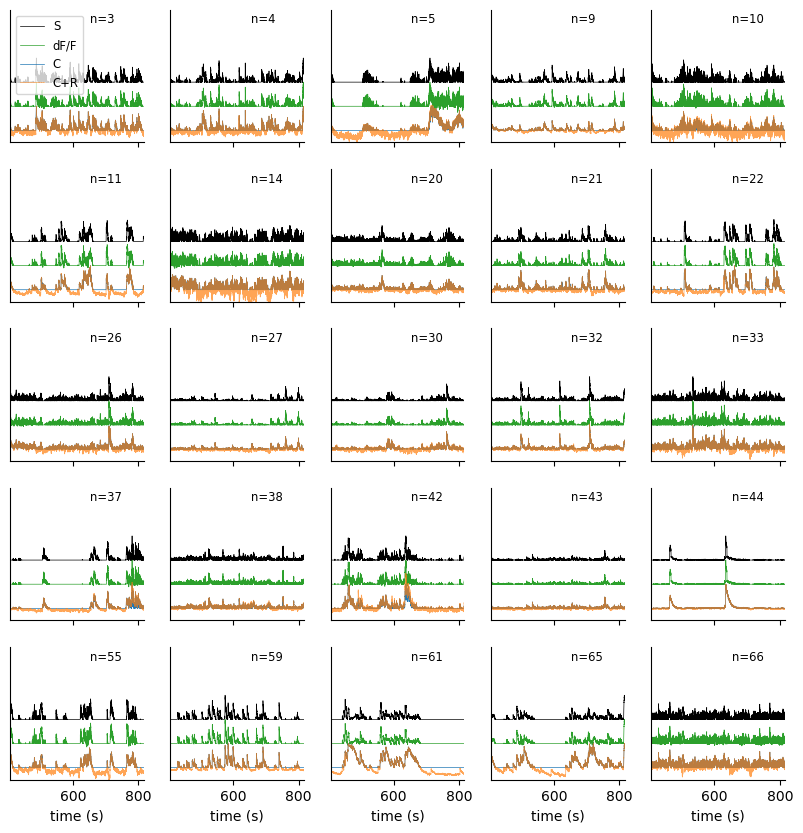

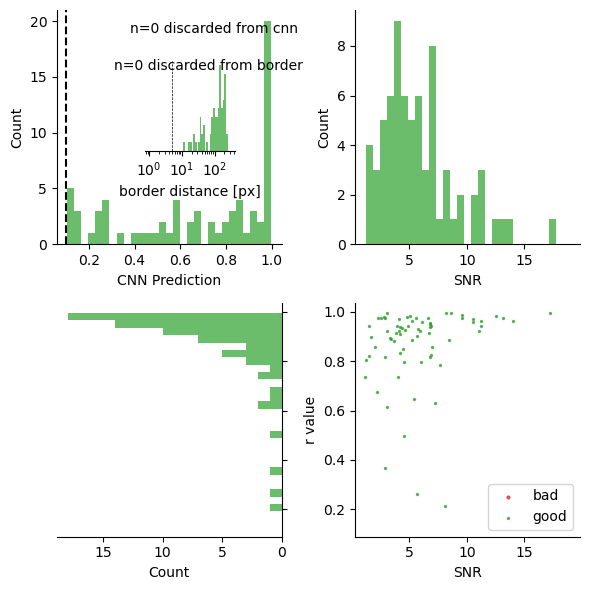

In [128]:
plot_contours(cnmf_batch.estimates, display_numbers=True)
plot_traces(cnmf_batch.estimates, f=30.05, n_plots=(5, 5))
plot_quality(cnmf_batch)

In [ ]:
cnmf_obj.save(str(result_path))

N = cnmf_obj.estimates.A.shape[-1]
print(f"\tNumber of components found: {N}")

	Number of components found: 1348
Detrended df/f


In [32]:
cnmf_batch = cnmf.cnmf.load_CNMF(str(result_path))
cnmf_batch.estimates.select_components(use_object=True, save_discarded_components=False)

Datafile ../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00001.hdf5 not marked as cnmf


In [34]:
cnmf_batch.estimates.select_components(use_object=True, save_discarded_components=False)
cnmf_batch.estimates.A.shape

(262144, 167)

In [ ]:
# del cnmf_batch_.estimates.S_dff

AttributeError: 'Estimates' object has no attribute 'S_dff'

In [ ]:
# cnmf_batch_.params.get_group("preprocess")
# cnmf_batch_.params.get_group("temporal")
f = 30.05
cnmf_batch_.estimates.detrend_df_f(
    quantileMin=8, frames_window=int(10 * f), flag_auto=False, use_residuals=False
)

In [66]:
cnmf_batch_.estimates.g

[array([ 1.88580208, -0.88892682]),
 array([ 1.88468468, -0.88788624]),
 array([ 1.86707399, -0.87093668]),
 array([ 1.88248089, -0.88583394]),
 array([ 1.88490947, -0.88809557]),
 array([ 1.88399541, -0.88724435]),
 array([ 1.8862919 , -0.88938297]),
 array([ 1.88716394, -0.89019506]),
 array([ 1.89059526, -0.89339051]),
 array([ 1.88661096, -0.8896801 ]),
 array([ 1.89050644, -0.89304417]),
 array([ 1.88465948, -0.88786277]),
 array([ 1.88924066, -0.89228906]),
 array([ 1.870225  , -0.87442054]),
 array([ 1.889526  , -0.89239476]),
 array([ 1.88341915, -0.8867077 ]),
 array([ 1.88821557, -0.8911744 ]),
 array([ 1.88873372, -0.89165694]),
 array([ 1.8777964 , -0.88147146]),
 array([ 1.92295052, -0.92440707]),
 array([ 1.88601586, -0.88912591]),
 array([ 1.88542642, -0.88857699]),
 array([ 1.88049687, -0.8839863 ]),
 array([ 1.87970175, -0.88324584]),
 array([ 1.88686079, -0.88991276]),
 array([ 1.88643001, -0.88951159]),
 array([ 1.88436482, -0.88758836]),
 array([ 1.8811296 , -0.8845

/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:554: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


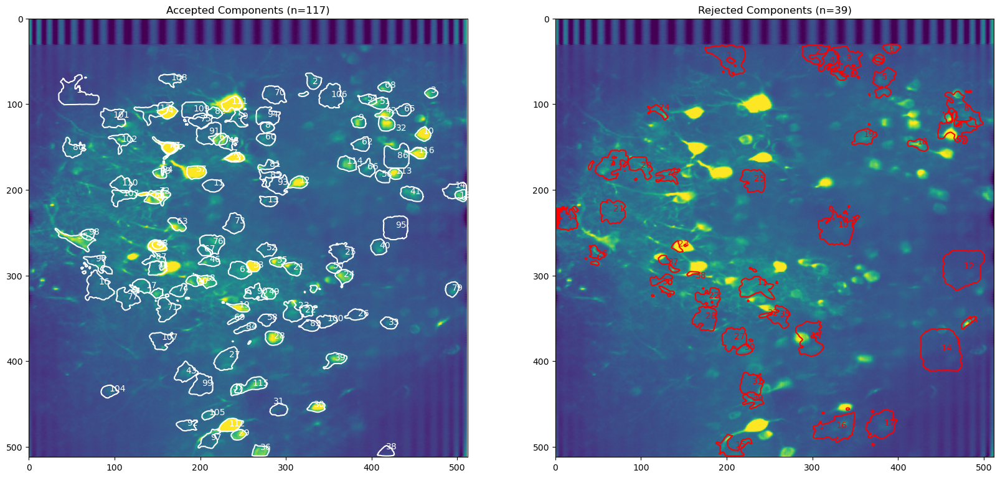

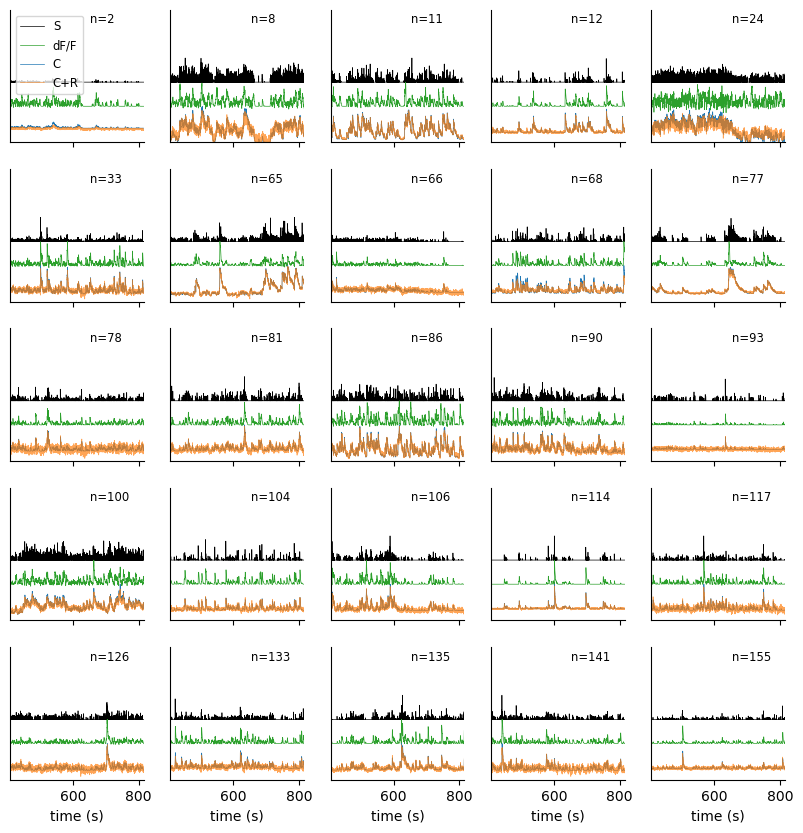

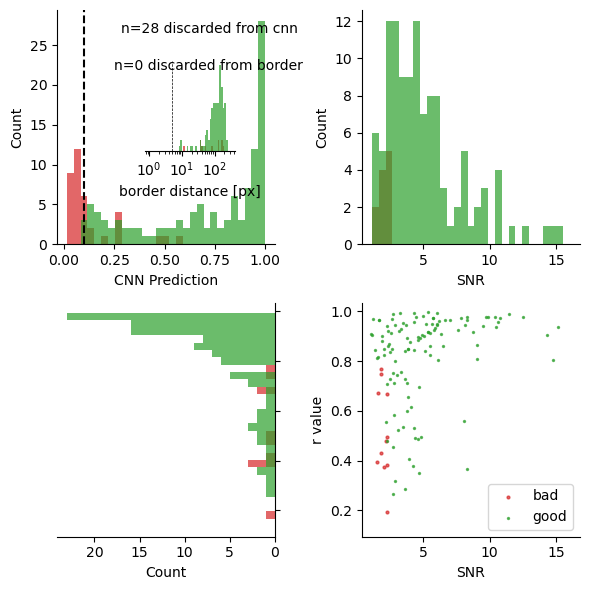

In [ ]:
from image_processing.neuron_detection import plot_contours, plot_quality, plot_traces

cnmf_ = cnmf_batch_  # cnmf_obj  #
plot_contours(cnmf_.estimates, display_numbers=True)
plot_traces(cnmf_.estimates, f=30.05, n_plots=(5, 5))
plot_quality(cnmf_)

In [ ]:
cnmf_batch_.estimates.

AttributeError: 'Estimates' object has no attribute 'F_dff_dec'

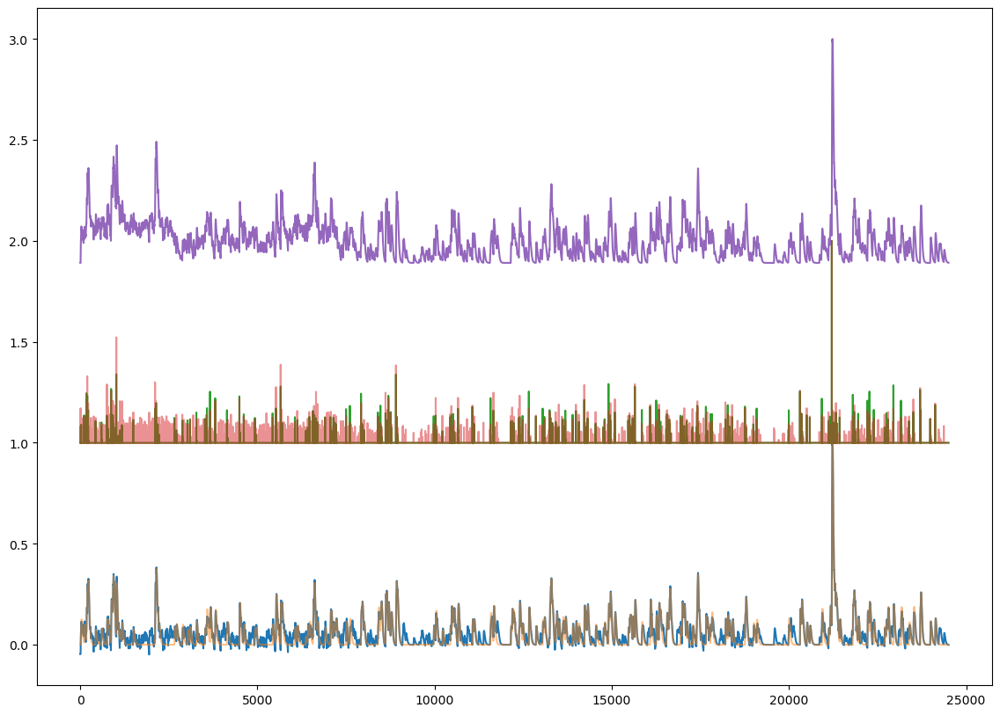

In [ ]:
# cnmf_batch_.params.get_group("merging")
plt.figure(figsize=(14, 10))
cnmf_ = cnmf_batch_  # cnmf_obj  #
n = 1
plt.plot(cnmf_.estimates.F_dff[n, :] / np.max(cnmf_.estimates.F_dff[n, :]))
plt.plot(
    cnmf_batch_.estimates.F_dff_dec[n, :]
    / np.max(cnmf_batch_.estimates.F_dff_dec[n, :]),
    alpha=0.5,
)
plt.plot(1 + cnmf_.estimates.S_dff[n, :] / np.max(cnmf_.estimates.S_dff[n, :]))
plt.plot(1 + cnmf_.estimates.S[n, :] / np.max(cnmf_.estimates.S[n, :]), alpha=0.5)
plt.plot(2 + cnmf_.estimates.C[n, :] / np.max(cnmf_.estimates.C[n, :]))
# cnmf_batch_.estimates.F_dff_dec.shape

In [55]:
if use_parallel:
    if "dview" in locals():  # 'locals' contains list of current local variables
        # print("Closing previous cluster")
        caiman.stop_server(dview=dview)
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_batch.estimates.deconvolve(cnmf_batch.params, dview=dview, dff_flag=False)
print("Deconvolution done")
# cnmf_batch.estimates.deconvolve(cnmf_batch.params, dview=dview, dff_flag=True)

KeyboardInterrupt: 

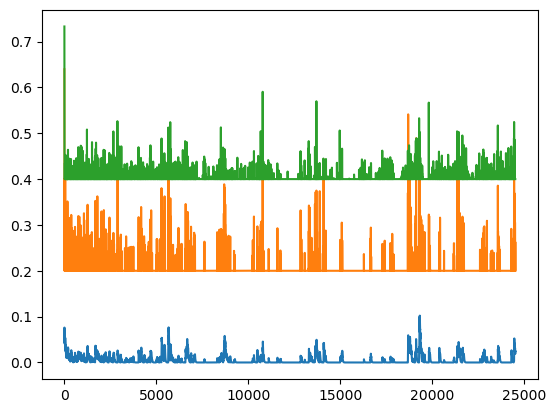

In [28]:
plt.figure()
plt.plot(cnmf_batch.estimates.F_dff_dec[0, :])
plt.plot(cnmf_batch.estimates.S_dff[0, :] * 10 + 0.2)
plt.plot(cnmf_batch.estimates.S[0, :] * 0.001 + 0.4)
# cnmf_batch.estimates.S_dff.shape

# cnmf_batch.estimates.A.shape

In [76]:
resultFile_name = f"batch_{prefix}_{Path(fname).stem}{suffix}"
result_path = session_path / f"{resultFile_name}.{save_type}"
print(result_path)
# cnmf_batch.save(str(result_path))

../../../../data/Subhodeep/ID45/20230912/batch_results_CaImAn_20230912_45_00001.hdf5


In [30]:
if use_parallel:
    if "dview" in locals():  # 'locals' contains list of current local variables
        # print("Closing previous cluster")
        caiman.stop_server(dview=dview)
    c, dview, n_processes = caiman.cluster.setup_cluster(
        n_processes=n_processes, single_thread=False
    )
else:
    dview = None
    n_processes = 1

cnmf_batch = post_processing(cnmf_batch, path_to_motion_correct, dview=dview)

Detrended df/f
Computed residuals
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
Evaluated components
Num accepted/rejected: 24, 143


In [26]:
# cnmf_batch.estimates.select_components(use_object=True, save_discarded_components=False)
cnmf_batch.estimates.C

array([[-0.00347485,  0.00086523,  0.00468288, ...,  0.01048612,
         0.00988436,  0.00929063],
       [-0.00021281, -0.00021281, -0.00021281, ...,  0.00900456,
         0.00881065,  0.00861204],
       [-0.0034237 , -0.0034237 , -0.0034237 , ..., -0.003007  ,
        -0.00301973, -0.0030321 ],
       ...,
       [-0.00047749, -0.00047749, -0.00047749, ...,  0.00310969,
         0.00295985,  0.00281504],
       [-0.00062833, -0.00062833, -0.00062833, ..., -0.00060273,
        -0.000604  , -0.00060521],
       [ 0.00208381,  0.00208381,  0.00208381, ...,  0.00877204,
         0.00871419,  0.00864404]])

In [19]:
cnmf_obj.estimates.C.shape

(1348, 24503)

In [11]:
"""
* check times at which neurons were added (how many during init phase?)
* check for shape of cn, neurons_cn, c1, ... (before / after eval and select)
* shape mismatches -> due to select_components? or why?
* merging currently not possible (due to shape mismatches?!)
* shapes look weird before refit -> check results after
"""

cnmf_obj.params

CNMFParams:

data:

{'caiman_version': '1.13.0',
 'decay_time': 1.5,
 'dims': (512, 512),
 'dxy': 0.9647998794000152,
 'fnames': [PosixPath('/home/wollex/caiman_data/temp/20230912_45_00001_els__d1_512_d2_512_d3_1_order_F_frames_24503.mmap')],
 'fr': 30.05,
 'last_commit': 'GITW-6f76c6e7aecfd5cc5387f08f1afd6b2692ccea5e',
 'var_name_hdf5': 'mov'}

init:

{'K': 30,
 'SC_kernel': 'heat',
 'SC_nnn': 20,
 'SC_normalize': True,
 'SC_sigma': 1,
 'SC_thr': 0,
 'SC_use_NN': False,
 'alpha_snmf': 0.5,
 'center_psf': False,
 'gSig': [10, 10],
 'gSiz': array([21, 21]),
 'greedyroi_nmf_init_method': 'nndsvdar',
 'greedyroi_nmf_max_iter': 200,
 'init_iter': 2,
 'kernel': None,
 'lambda_gnmf': 1,
 'maxIter': 5,
 'max_iter_snmf': 500,
 'method_init': 'greedy_roi',
 'min_corr': 0.85,
 'min_pnr': 20,
 'nIter': 5,
 'nb': 2,
 'normalize_init': True,
 'options_local_NMF': None,
 'perc_baseline_snmf': 20,
 'ring_size_factor': 1.5,
 'rolling_length': 100,
 'rolling_sum': True,
 'seed_method': 'auto',
 'sigma_

In [7]:
cnmf_obj.estimates.discarded_components = None

In [10]:
cnmf_obj.estimates.A.shape

(262144, 36)

In [ ]:
# ## find and remove neurons which are too close to the border
# ## (often sliced or with border effects)
# border_thr = 5
# cnmf_obj.estimates.coordinates = caiman.utils.visualization.get_contours(
#     cnmf_obj.estimates.A, cnmf_obj.estimates.dims, thr=0.2, thr_method="max"
# )

# idx_border = []
# for n in range(N):

#     if (cnmf_obj.estimates.coordinates[n]["CoM"] < border_thr).any() or (
#         cnmf_obj.estimates.coordinates[n]["CoM"]
#         > (cnmf_obj.estimates.dims[0] - border_thr)
#     ).any():
#         idx_border.append(n)

# cnmf_obj.estimates.idx_components = np.setdiff1d(
#     cnmf_obj.estimates.idx_components, idx_border
# ).astype(int)
# cnmf_obj.estimates.idx_components_bad = np.union1d(
#     cnmf_obj.estimates.idx_components_bad, idx_border
# ).astype(int)

TypeError: object of type 'NoneType' has no len()

TypeError: '<' not supported between instances of 'NoneType' and 'float'

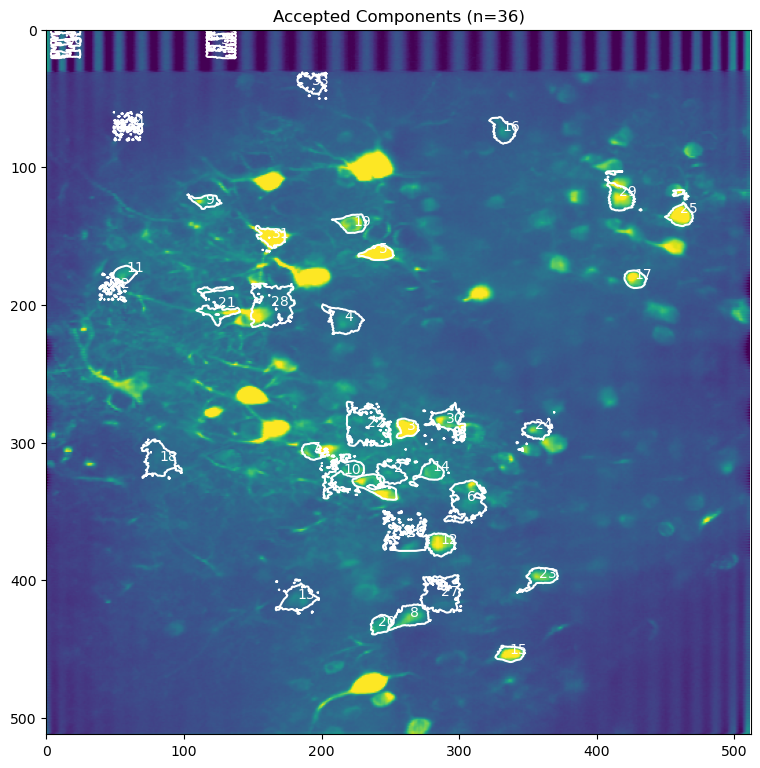

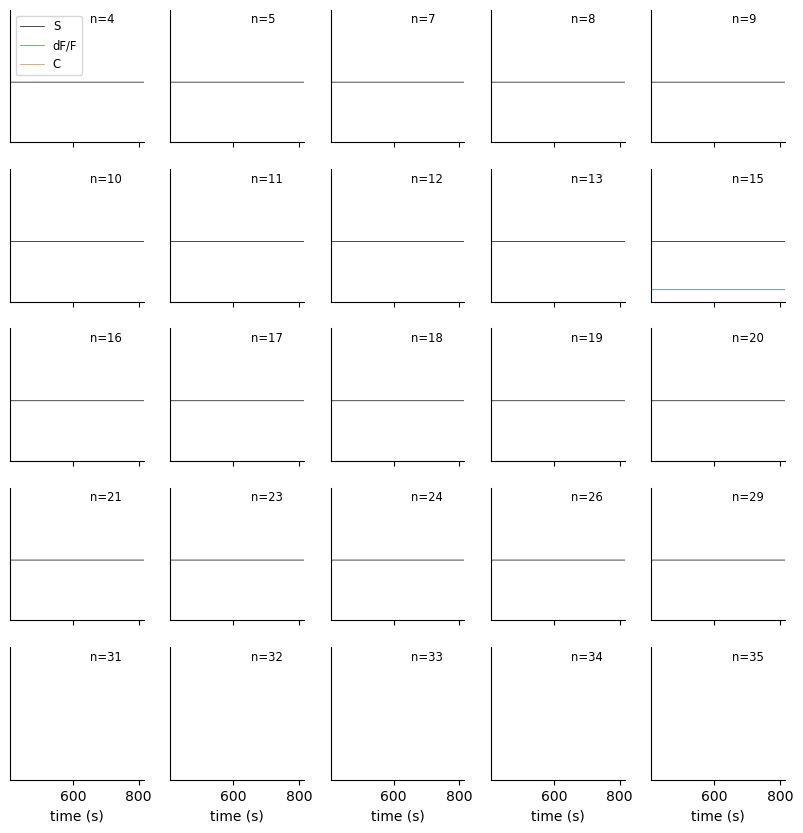

<Figure size 600x600 with 0 Axes>

In [12]:
from image_processing.neuron_detection import plot_contours, plot_quality, plot_traces

plot_contours(cnmf_obj.estimates, display_numbers=True)
plot_traces(cnmf_obj.estimates, f=30.05, n_plots=(5, 5))
plot_quality(cnmf_obj)

In [31]:
cnmf_batch.estimates.A.shape

(262144, 1348)

/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:554: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


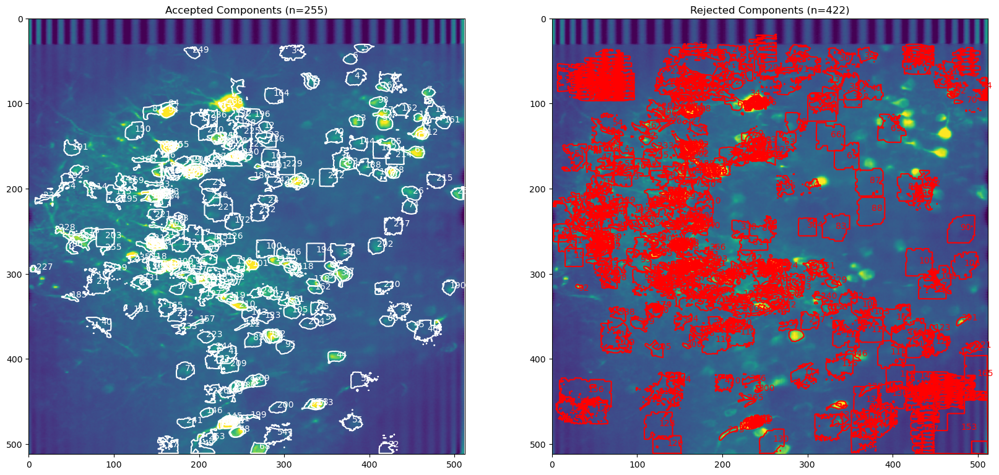

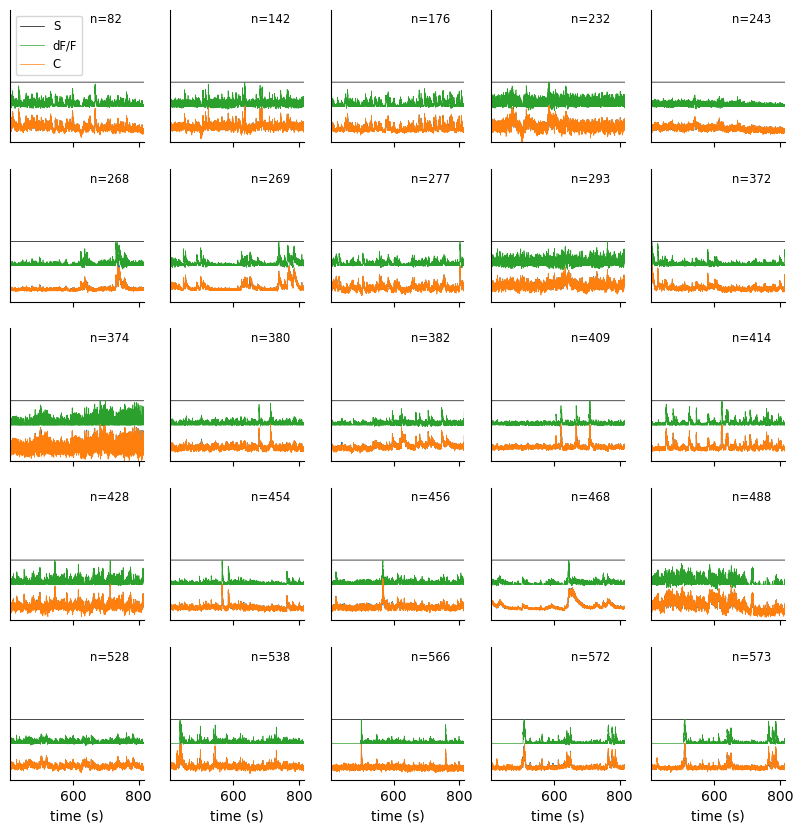

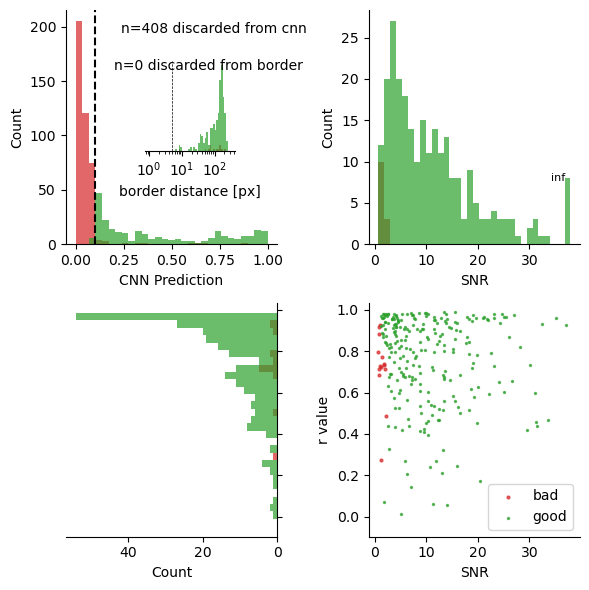

In [18]:
plot_contours(cnmf_obj.estimates, display_numbers=True)
plot_traces(cnmf_obj.estimates, f=30.05, n_plots=(5, 5))
plot_quality(cnmf_obj)

<string>:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


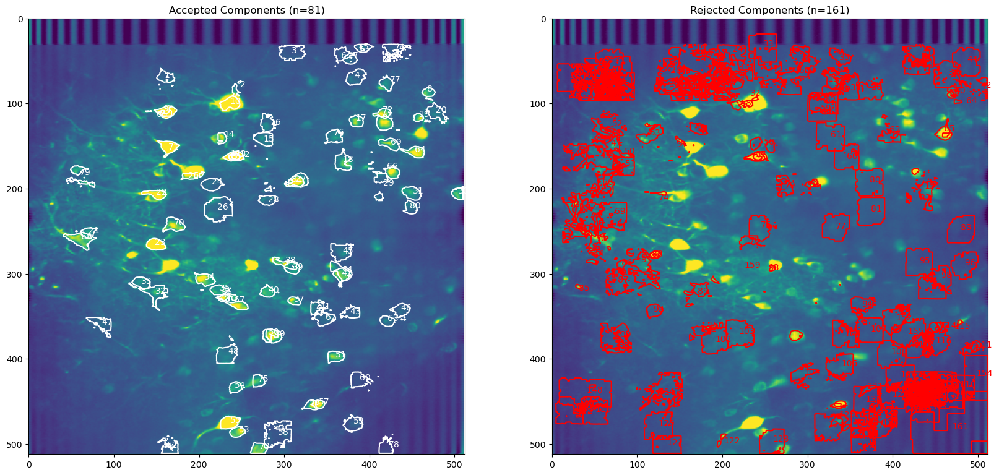

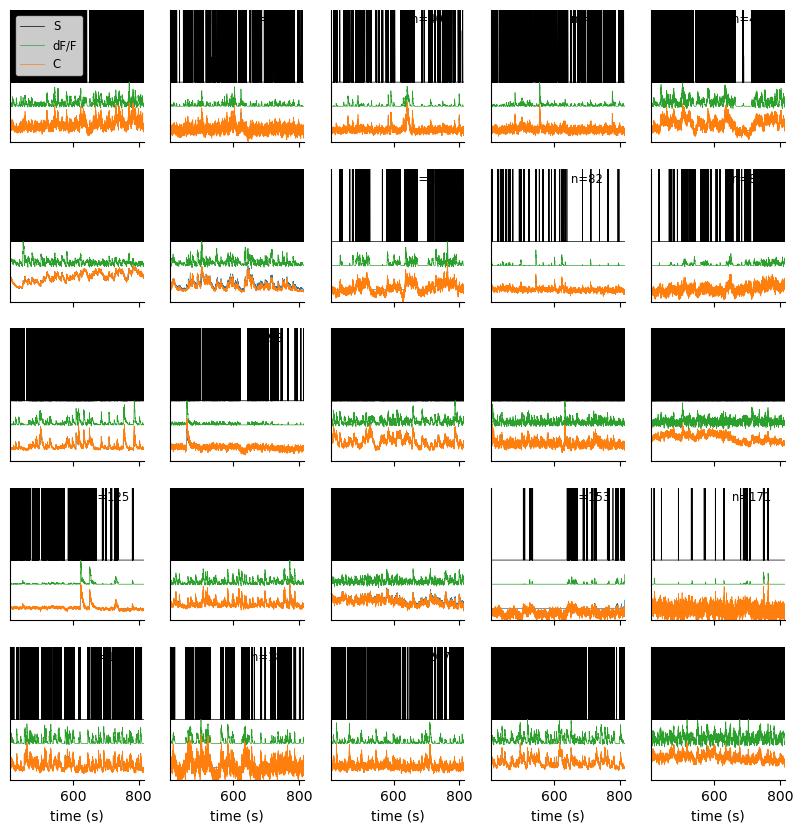

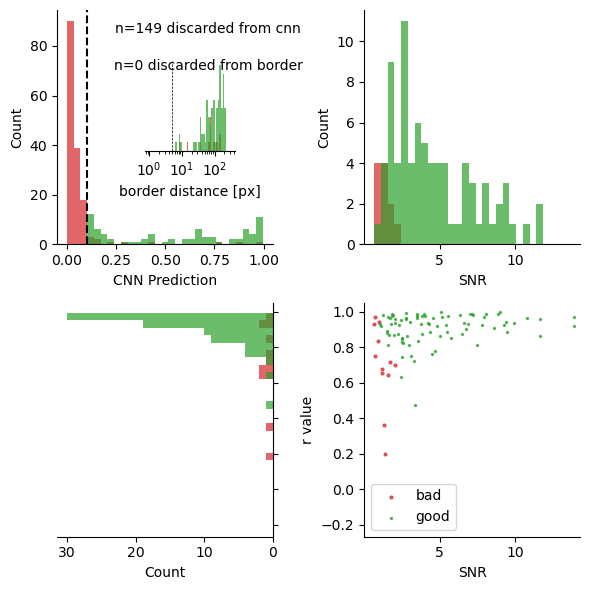

In [55]:
Yr, dims, num_frames = caiman.load_memmap(str(path_to_motion_correct))
images = np.reshape(Yr.T, [num_frames] + list(dims), order="C")
if "dview" in locals():  # 'locals' contains list of current local variables
    caiman.stop_server(dview=dview)
c, dview, n_processes = caiman.cluster.setup_cluster(
    n_processes=n_processes, single_thread=False
)
cnmf_obj.mmap_file = str(path_to_motion_correct)
# cnmf_obj.estimates.merge_components(Yr, cnmf_obj.params, dview=dview)
cnmf_refitted = cnmf_obj.refit(
    images, dview=dview
)  # refit to get the new temporal components // should include merging already!

In [89]:
from scipy.spatial.distance import pdist, squareform

centers = [coord["CoM"] for coord in cnmf_refitted.estimates.coordinates]
# centers

distances = squareform(pdist(centers))
np.fill_diagonal(distances, np.nan)
min_dist = np.nanargmin(distances, axis=0)
# min_dist[np.where(min_dist<5)]
min_dist

array([119, 223,  60,   6,   6,   6,   5,  14,   9,   8, 191, 229,  94,
       129,  13,  84, 167, 167,  59, 212, 179,  58,  88, 145,  87,  26,
        25, 189,  29,  28,  75,  47, 102,  71,  41, 201, 213, 205,  54,
        40,  39,  42,  41,  44,  43,  53, 168,  31, 129,  97,  81, 150,
        96,  45,  38,   4,  12,  40,  21,  18,   2,  83, 183, 227, 101,
       142, 160,  96, 176, 149, 149,  33, 204,  88,  63,  78,  96, 171,
        75,  53, 126,  50, 200,  61,  15, 145, 141,  24,  22, 107, 118,
       126,  86,  53,  79, 136,  52,  49, 204, 146,  72,  64, 152, 176,
        99, 214,  95,  69, 111, 217, 113, 108, 115, 110, 150, 108, 105,
       213,  90, 158,  28,  10, 219,  97, 189, 190,  91, 154,  79,  13,
       226, 178,  64, 163, 203, 196,  25, 220, 186, 211, 210,  86, 194,
       227, 221,  85, 154, 230, 199,  70,  51, 142,  22, 170, 146, 137,
       144,  31, 119,   9,  66, 203,  23, 133, 171, 208, 192,  17,  46,
       229, 153, 164, 174, 204, 172, 225,  68,  73, 131,  20,  5

In [ ]:
#
cnmf_refitted.estimates.merge_components(
    Yr, cnmf_refitted.params, fast_merge=True, dview=dview
)

IndexError: list index out of range

In [49]:
def ar2_to_tau(a1, a2, f):
    dt = 1 / f
    discriminant = a1**2 + 4 * a2
    lambda1 = (a1 + np.sqrt(discriminant)) / 2
    lambda2 = (a1 - np.sqrt(discriminant)) / 2
    tau1 = -dt / np.log(np.abs(lambda1))
    tau2 = -dt / np.log(np.abs(lambda2))
    return tau1, tau2


GCaMP6s = (0.18, 0.58)
GCaMP6m = (0.1, 0.289)
GCaMP6f = (0.03, 0.15)

ar2_to_tau(*cnmf_obj.estimates.g[0], cnmf_obj.params.get("data", "fr"))

(0.42956231515005683, 0.017187338342483077)

In [103]:
plot_contours(cnmf_obj.estimates, display_numbers=True)
plot_traces(cnmf_obj.estimates, f=cnmf_obj.params.get("data", "fr"))
plot_quality(cnmf_obj)

AttributeError: 'Estimates' object has no attribute 'Cn'

In [ ]:
thereafter, test consistency of result shapes
then test selecting components and consistency
then test refit and consistency, ...


<string>:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.


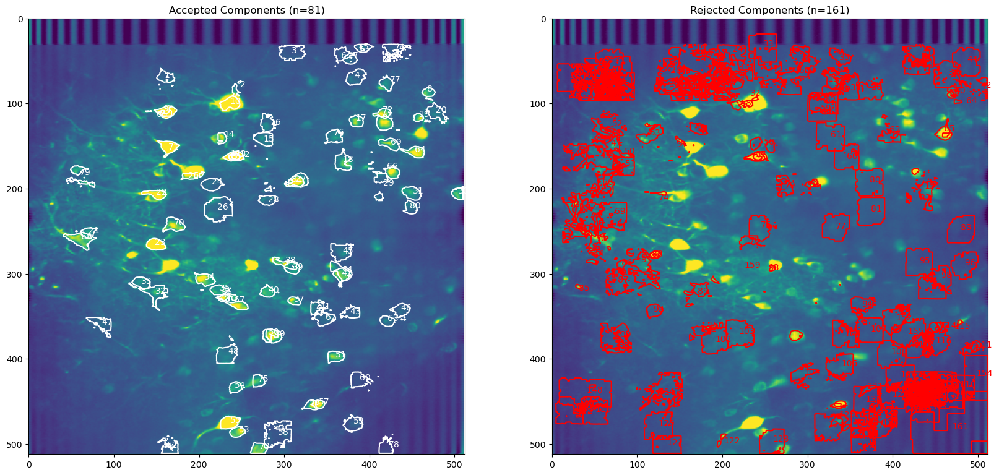

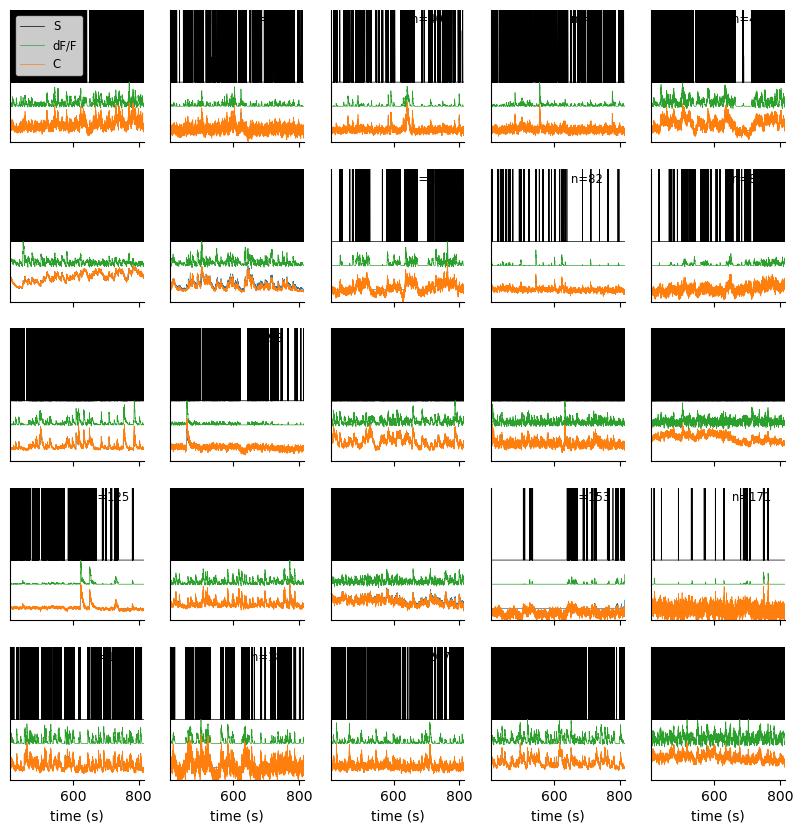

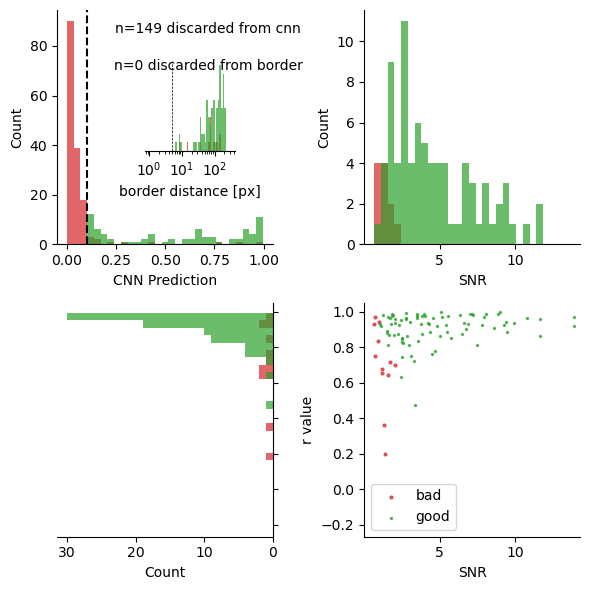

In [123]:
cnmf_obj.estimates.Cn = Cn
f = 30.05
plot_contours(cnmf_obj.estimates, display_numbers=True)
plot_traces(cnmf_obj.estimates, f=f, n_plots=(5, 5))
plot_quality(cnmf_obj)

In [6]:
# [cnmf_obj.estimates.coordinates[cr] for cr in cnmf_obj.estimates.idx_components_bad]
cnmf_obj.estimates.idx_components_bad
# [cr for cr in cnmf_obj.estimates.idx_components_bad]

NameError: name 'cnmf_obj' is not defined

[ 13  18  27  53  56  67  69  79  80 105 108 123 131 143 145 159 185 229
 236 238 240 247 251 256 266 267 296 316 327 351 359 365 367 387 393 395
 410 438 471 480 482 484 495 496 506 520 533 535 553 554 558 579 596 607
 611 636]


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:548: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


[]


/home/wollex/Data/Science/WolfGroup/PlaceFields/Programs/representational-turnover-analysis/turnover_dynamics/neuron_detection_caiman/image_processing/neuron_detection.py:548: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


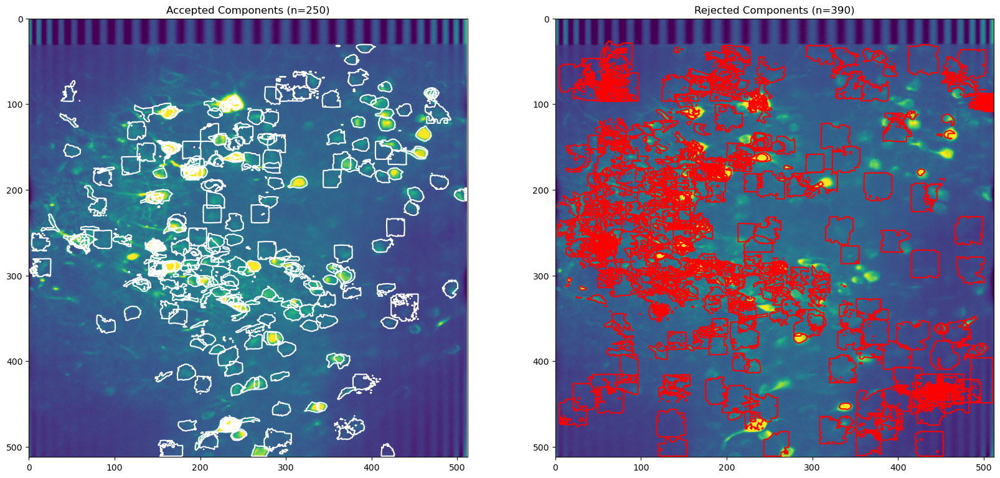

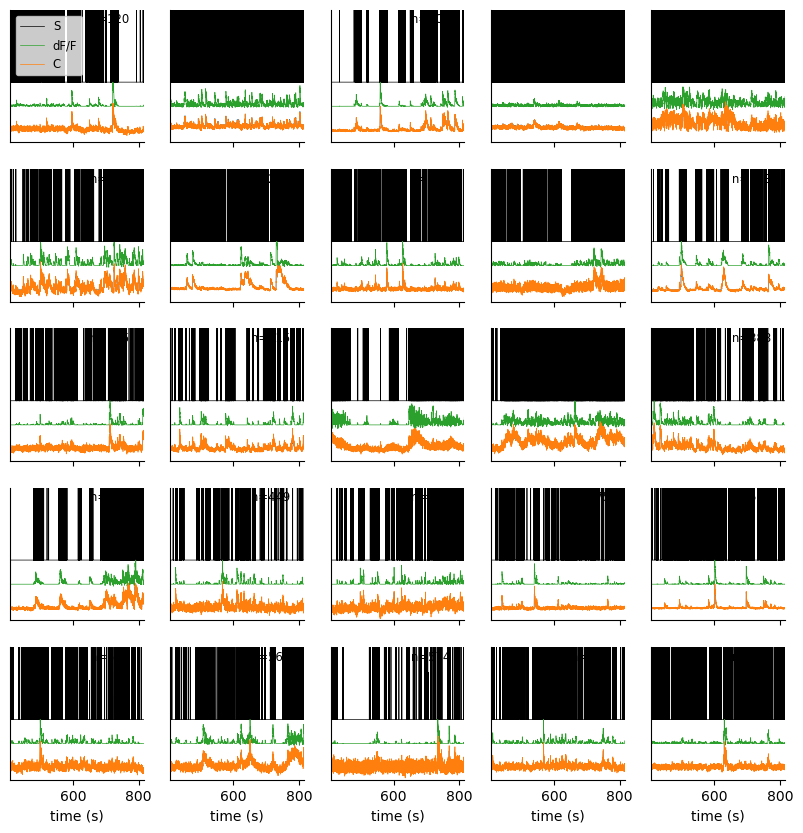

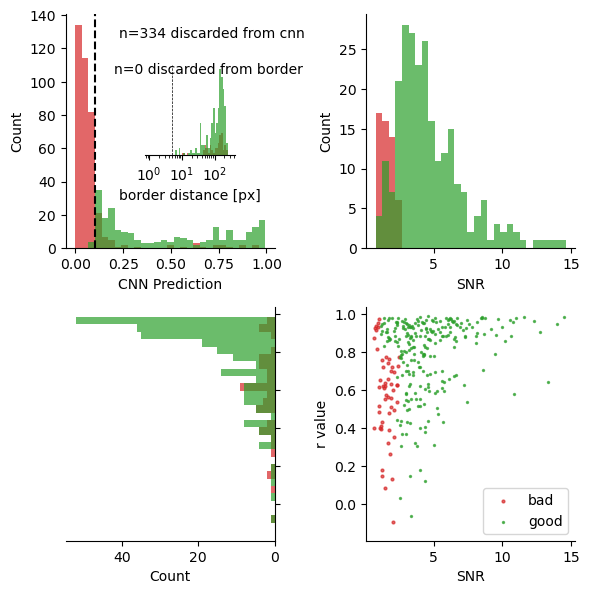

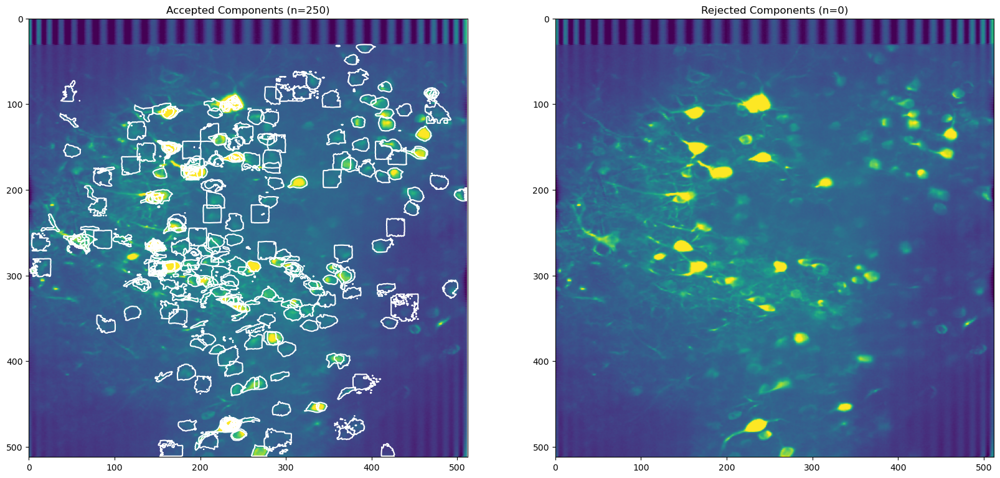

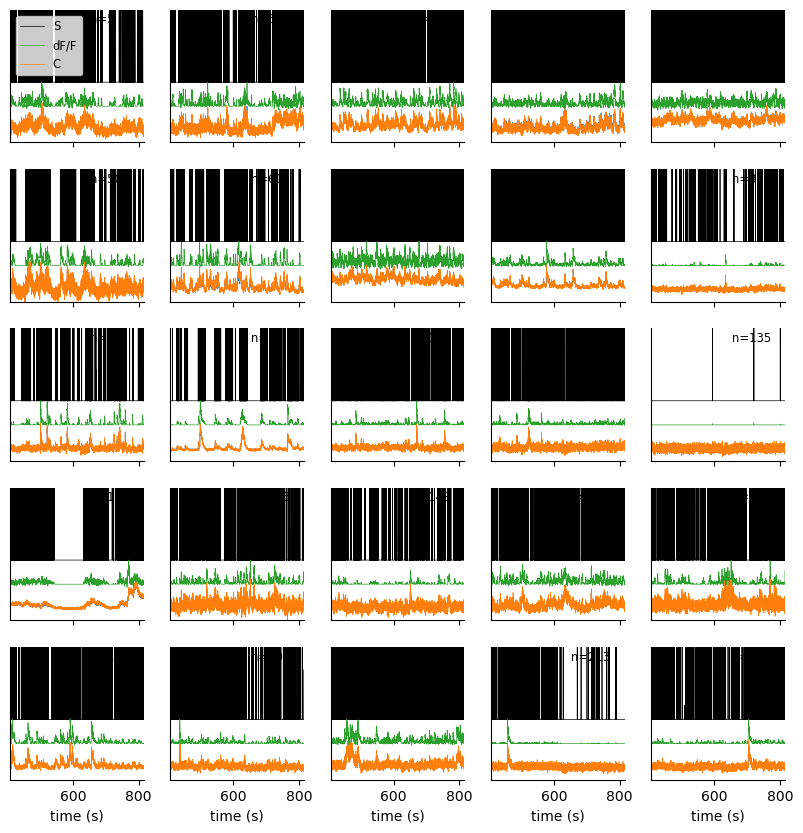

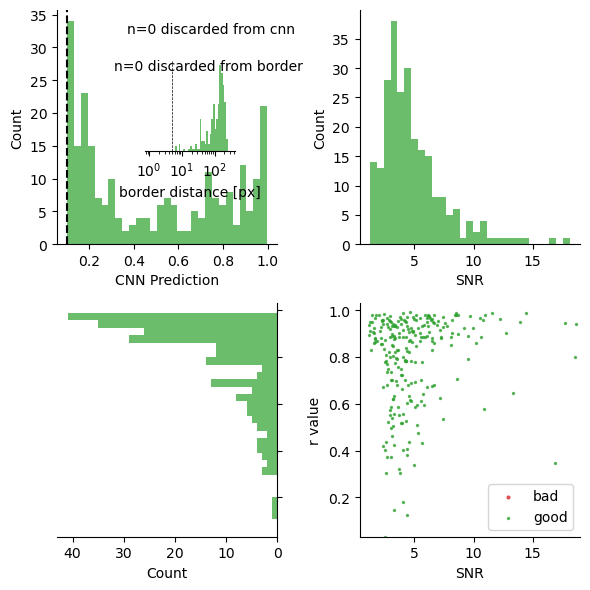

In [ ]:
from image_processing.neuron_detection import plot_contours, plot_traces, plot_quality

figure_path = session_path / "figures"
cnmf_obj.estimates.Cn = Cn

for cnmf_ in [cnmf_obj, cnmf_batch]:
    plot_contours(cnmf_.estimates, figure_path=figure_path, thr=0.2)
    plot_traces(cnmf_.estimates, f=f, figure_path=figure_path, n_plots=(5, 5))
    plot_quality(cnmf_, figure_path=figure_path)

In [42]:
cnmf_batch = cnmf.cnmf.load_CNMF(str(session_path / (save_name + f".{save_type}")))

Datafile ../../../../data/Subhodeep/ID45/20230912/results_CaImAn_20230912_45_00001_els__d1_512_d2_512_d3_1_order_F_frames_24503.hdf5 not marked as cnmf


In [ ]:
cnmf_batch.estimates.idx_components_bad = cnmf_obj.estimates.idx_components_bad.astype(
    int
)

In [ ]:
cnmf_batch.estimates.select_components(
    cnmf_obj.estimates.idx_components, save_discarded_components=False
)

*** Variable g has not the same number of components as A ***
*** Variable c1 has not the same number of components as A ***
*** Variable neurons_sn has not the same number of components as A ***
*** Variable lam has not the same number of components as A ***


(24503, 512, 512)


Caiman CNMF Object A.shape=(262144, 195) bg components=2 C.shape=(195, 24503) Use str() for more details

In [59]:
cnmf_batch.estimates.evaluate_components(images, cnmf_batch.params, dview=dview)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [11]:
import pickle

output_path = session_path / "figures"
mc_results_path = f"{session_path}/motion_correction_summary_20230912_45_00001.pkl"
with open(mc_results_path, "rb") as f:
    ld = pickle.load(f)

In [13]:
ld["Cn"]

array([[0.28483403, 0.23787045, 0.14497764, ..., 0.27189568, 0.23704189,
        0.16585166],
       [0.2064722 , 0.22270485, 0.19036391, ..., 0.20836816, 0.23499897,
        0.21486645],
       [0.20893811, 0.22996569, 0.19546641, ..., 0.20382423, 0.23662177,
        0.22090104],
       ...,
       [0.10006598, 0.10613685, 0.08587541, ..., 0.17813803, 0.20914101,
        0.18933247],
       [0.13025691, 0.13635589, 0.10510803, ..., 0.17759249, 0.20672119,
        0.18720773],
       [0.16871003, 0.13057272, 0.07511308, ..., 0.23179335, 0.21150841,
        0.14743801]])

In [ ]:
import cv2

cv2.destroyAllWindows()
# import multiprocessing
# for p in multiprocessing.active_children():
#     p.terminate()

In [ ]:
import numpy as np

x_shifts_rig, y_shifts_rig = np.percentile(mc.shifts_rig, [1, 99], axis=0).T
shifts = {
    "rigid": {
        "x_shifts": np.array(mc.shifts_rig)[:, 0],
        "y_shifts": np.array(mc.shifts_rig)[:, 1],
        "x_shifts_max": x_shifts_rig,
        "y_shifts_max": y_shifts_rig,
    },
    "piecewise": {
        "x_shifts": mc.x_shifts_els,
        "y_shifts": mc.y_shifts_els,
        "x_shifts_max": np.percentile(np.concatenate(mc.x_shifts_els), [1, 99], axis=0),
        "y_shifts_max": np.percentile(np.concatenate(mc.y_shifts_els), [1, 99], axis=0),
    },
}
m_rig = caiman.load(mc.mmap_file)
Cn = caiman.local_correlations(m_rig, swap_dim=False)

results = {
    "motion_corrected_file": mc.mmap_file[0],
    "shifts": shifts,
    "Cn": Cn,
    "template": mc.total_template_els,
}

100%|██████████| 1/1 [01:11<00:00, 71.70s/it]


In [ ]:
import pickle

with open(f"{session_path}/motion_correction_shifts_{Path(fname).stem}.pkl", "wb") as f:
    pickle.dump(results, f)

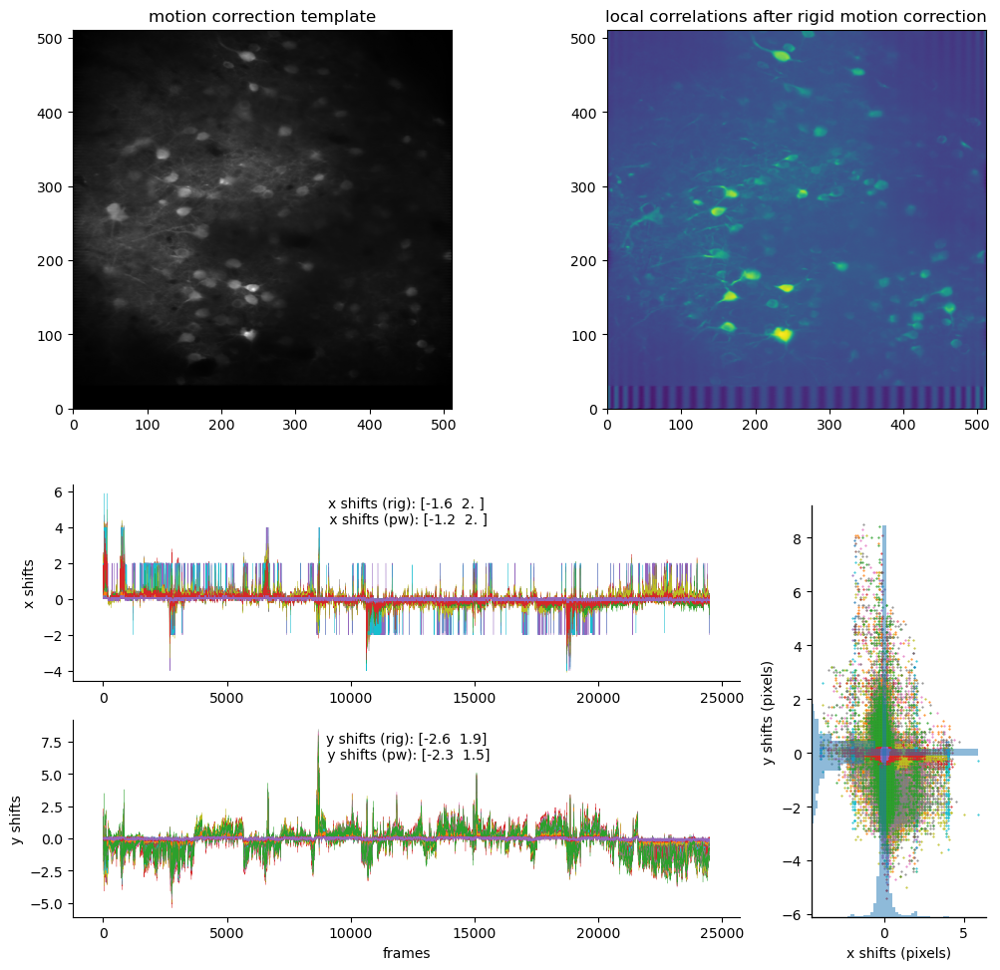

In [ ]:
from image_processing.motion_correct import plot_results_motion_correction

plot_results_motion_correction(
    results["shifts"],
    results["Cn"],
    results["template"],
    figure_path=f"{session_path}/figures/motion_correction_summary_{Path(fname).stem}.png",
)

In [13]:
m_rig = caiman.load(mc.mmap_file)
Cn = caiman.local_correlations(m_rig, swap_dim=False)

100%|██████████| 1/1 [00:39<00:00, 39.16s/it]


In [ ]:
session_path = Path("../../../../data/KotaroData/493_copy/Session03/")
# file_path = [file for file in session_path.iterdir() if file.suffix == ".tif"][0]
path_to_motion_correct = [
    file for file in session_path.iterdir() if file.suffix == ".mmap"
][0]
# print(file_path)
fname = str(path_to_motion_correct)

n_processes = 12
prefix = "results_CaImAn"
suffix = ""
save_type = "hdf5"
resultFile_name = f"{prefix}_{Path(fname).stem}{suffix}"
print(f"finally, saving file to {resultFile_name}")

params = copy.deepcopy(CaImAn_params)

os.environ["CAIMAN_DATA"] = str(Path.home() / "caiman_data")
os.environ["CAIMAN_TEMP"] = str(session_path)
neuron_detection(
    path_to_motion_correct,
    params,
    save_name=resultFile_name,
    n_processes=n_processes,
    save_type=save_type,
)

# run_detection(
#     fname,
#     suffix="_test",
# )

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


finally, saving file to results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_98um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162
in the end, saving results to: ../../../../data/KotaroData/493_copy/Session03/results_CaImAn_df1cko#493_m2_hp_x16_x1.5_15v_98um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.hdf5
	Now running neuron detection @t = Tue Dec 16 16:00:21 2025


Now processing file ../../../../data/KotaroData/493_copy/Session03/df1cko#493_m2_hp_x16_x1.5_15v_98um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap
/home/wollex/miniforge3/envs/caiman/lib/python3.11/site-packages/caiman/components_evaluation.py:112: RuntimeWarning: invalid value encountered in divide
  sd_r = np.sqrt(np.sum(ff1**2, 1) / Ns)
Now processing file ../../../../data/KotaroData/493_copy/Session03/df1cko#493_m2_hp_x16_x1.5_15v_98um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162.mmap


In [4]:
import torch

print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 5070


In [ ]:
import os
from image_processing.neuron_detection import neuron_detection
from utils.parameters import CaImAn as CaImAn_params

import caiman as cm
from caiman.source_extraction import cnmf as cnmf
from caiman.motion_correction import MotionCorrect
from pprint import pprint


session_path = Path("../../../../data/KotaroData/493_copy/Session02/")
file_path = [file for file in session_path.iterdir() if file.suffix == ".tif"][0]
print(file_path)
fname = [str(file_path)]
os.environ["CAIMAN_TEMP"] = str(session_path)

params = CaImAn_params
params["fr"] = 15.0
params["decay_time"] = 0.47
params["p"] = 2


# params["splits_rig"] = 10
save_name = "results_CaImAn.hdf5"
n_processes = 8
save_type = "hdf5"

# save_name = os.path.join(os.path.split(fname)[0], save_name)

params["fnames"] = [str(file_path)]
opts = cnmf.params.CNMFParams(params_dict=params)

if "dview" in locals():  # 'locals' contains list of current local variables
    print("Closing previous cluster")
    cm.stop_server(dview=dview)

c, dview, n_processes = cm.cluster.setup_cluster(
    backend="multiprocessing", n_processes=4, single_thread=False
)
## run the actual motion correction algorithm
# pprint(opts.get_group("motion"))
mc = MotionCorrect(fname, dview=dview, **opts.get_group("motion"))
mc.motion_correct(save_movie=False)

# pprint(opts.get_group("motion"))
# pprint(opts.get_group("online"))

# results_path = neuron_detection(
#     fname=str(file_path),
#     params=params,
#     save_name=save_name,
#     n_processes=n_processes,
#     save_type=save_type,
# )

In setting CNMFParams, non-pathed parameters were used; this is deprecated. In some future version of Caiman, allow_legacy will default to False (and eventually will be removed)


../../../../data/KotaroData/493_copy/Session02/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t.tif
Closing previous cluster


In [4]:
import numpy as np

bord_px_rig = np.ceil(np.max(mc.shifts_rig)).astype(int)
bord_px_rig

7

In [15]:
## calculate shifts
# rigid
rigshifts_max = np.max(mc.shifts_rig, axis=0)
rigshifts_min = np.min(mc.shifts_rig, axis=0)
x_shifts_rig = (np.floor(rigshifts_min[0]), np.ceil(rigshifts_max[0]))
y_shifts_rig = (np.floor(rigshifts_min[1]), np.ceil(rigshifts_max[1]))

x_shifts_rig, y_shifts_rig = np.percentile(mc.shifts_rig, [1, 99], axis=0).T
print(f"x shifts rigid: {x_shifts_rig}, y shifts rigid: {y_shifts_rig}")
# piecewise
x_max_shift = [(-min(shift), max(shift)) for shift in mc.x_shifts_els]
x_shifts = np.max(x_max_shift, axis=0)
x_shifts = (np.floor(-x_shifts[0]), np.ceil(x_shifts[1]))

y_max_shift = [(-min(shift), max(shift)) for shift in mc.y_shifts_els]
y_shifts = np.max(y_max_shift, axis=0)
y_shifts = (np.floor(-y_shifts[0]), np.ceil(y_shifts[1]))
print(f"x shifts piecewise: {x_shifts}, y shifts piecewise: {y_shifts}")

x_shifts_pw = np.percentile(np.concatenate(mc.x_shifts_els), [1, 99], axis=0)
print(f"x shifts piecewise 1-99 percentile: {x_shifts_pw}")

y_shifts_pw = np.percentile(np.concatenate(mc.y_shifts_els), [1, 99], axis=0)
print(f"y shifts piecewise 1-99 percentile: {y_shifts_pw}")

[-2.1  1.8] [-1.6  2.4]
x shifts rigid: [-2.1  1.8], y shifts rigid: [-1.6  2.4]
x shifts piecewise: (-6.0, 9.0), y shifts piecewise: (-5.0, 8.0)
x shifts piecewise 1-99 percentile: [-2.3  2. ]
y shifts piecewise 1-99 percentile: [-1.6  2.6]


In [104]:
Path(fname[0]).stem

'df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t'

(rigid) x shifts: [-2.1  1.8], y shifts: [-1.6  2.4]
(piecewise) x shifts: [-2.3  2. ], y shifts: [-1.6  2.6]


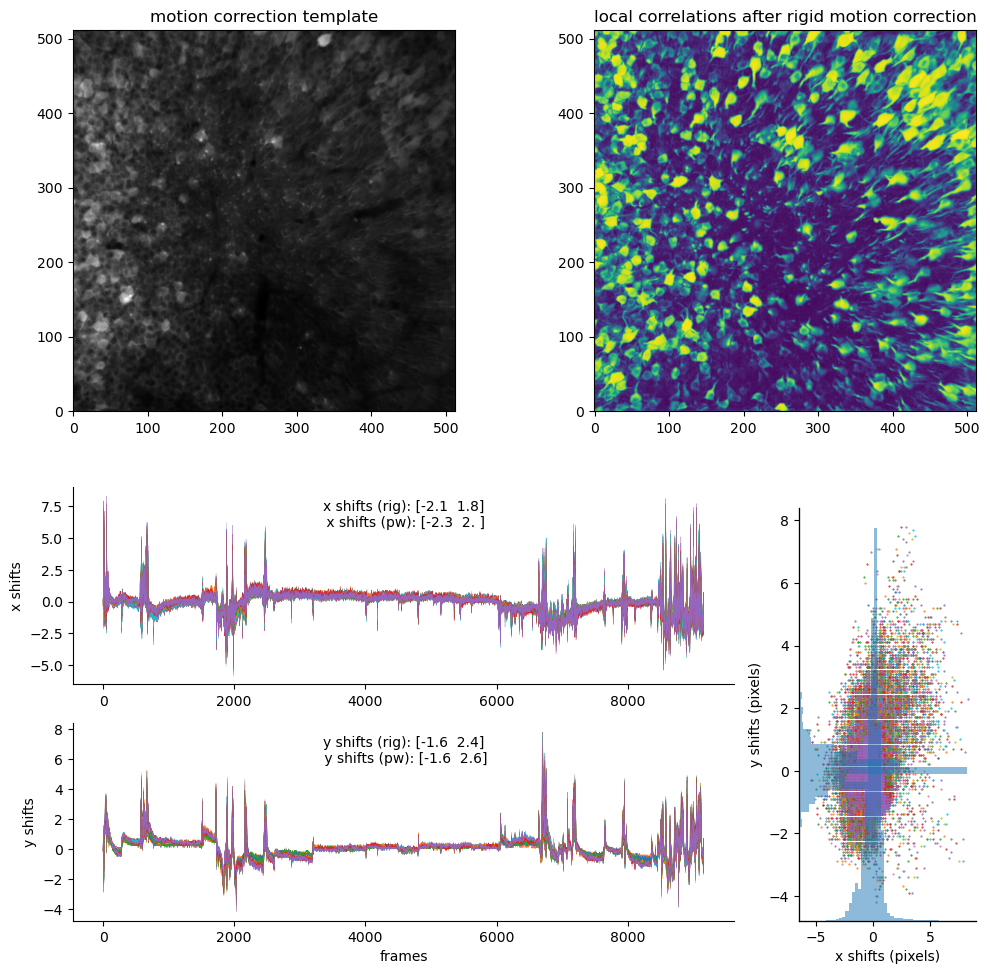

In [21]:
# m_rig = cm.load(
#     mc.mmap_file,
#     outtype=np.float16,
# )
# local_correlations = m_rig.local_correlations(eight_neighbours=True, swap_dim=False)

## calculate shifts
# rigid
x_shifts_rig, y_shifts_rig = np.percentile(mc.shifts_rig, [1, 99], axis=0).T
print(f"(rigid) x shifts: {x_shifts_rig}, y shifts: {y_shifts_rig}")
# piecewise
x_shifts_pw = np.percentile(np.concatenate(mc.x_shifts_els), [1, 99], axis=0)
y_shifts_pw = np.percentile(np.concatenate(mc.y_shifts_els), [1, 99], axis=0)
print(f"(piecewise) x shifts: {x_shifts_pw}, y shifts: {y_shifts_pw}")


fig = plt.figure(figsize=(10, 10))
plt.subplot(2, 2, 1)
plt.imshow(mc.total_template_els, origin="lower", cmap="gray")
plt.title("motion correction template")
plt.subplot(2, 2, 2)
plt.imshow(local_correlations, origin="lower", cmap="viridis")
plt.title("local correlations after rigid motion correction")

plt.subplot(4, 4, (9, 11))
plt.plot(mc.x_shifts_els, linewidth=0.2)
plt.text(
    0.5,
    0.8,
    f"x shifts (rig): {x_shifts_rig}\n x shifts (pw): {x_shifts_pw}",
    transform=plt.gca().transAxes,
    ha="center",
)
plt.ylabel("x shifts")
plt.gca().spines[["top", "right"]].set_visible(False)

plt.subplot(4, 4, (13, 15))
plt.plot(mc.y_shifts_els, linewidth=0.2)
plt.xlabel("frames")
plt.ylabel("y shifts")
plt.text(
    0.5,
    0.8,
    f"y shifts (rig): {y_shifts_rig}\n y shifts (pw): {y_shifts_pw}",
    transform=plt.gca().transAxes,
    ha="center",
)
plt.gca().spines[["top", "right"]].set_visible(False)


ax_scatter = plt.subplot(2, 4, 8)

ax = ax_scatter.twinx()
ax.hist(np.concatenate(mc.x_shifts_els), bins=50, alpha=0.5, color="C0")
plt.setp(ax, yticks=[])
ax.spines[["top", "right"]].set_visible(False)

ax = ax_scatter.twiny()
ax.hist(
    np.concatenate(mc.y_shifts_els),
    bins=50,
    alpha=0.5,
    color="C0",
    orientation="horizontal",
)
plt.setp(ax, xticks=[])
ax.spines[["top", "right"]].set_visible(False)

ax_scatter.plot(
    mc.x_shifts_els,
    mc.y_shifts_els,
    marker=".",
    markersize=1.0,
    markeredgecolor=None,
    linestyle="None",
    alpha=1.0,
)
plt.setp(ax_scatter, xlabel="x shifts (pixels)", ylabel="y shifts (pixels)")
ax_scatter.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{session_path}/motion_correction_summary.png", dpi=150)

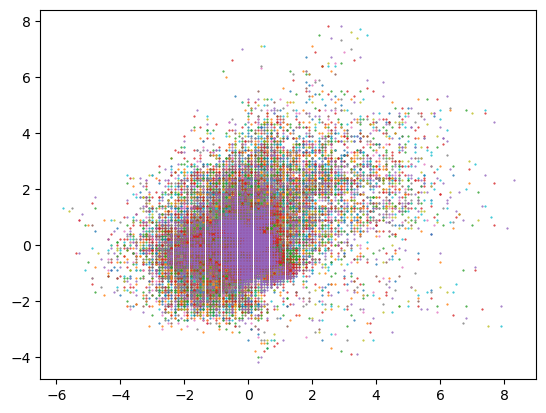

In [67]:
plt.figure()
plt.plot(mc.x_shifts_els, mc.y_shifts_els, marker=".", markersize=1, linestyle="None")

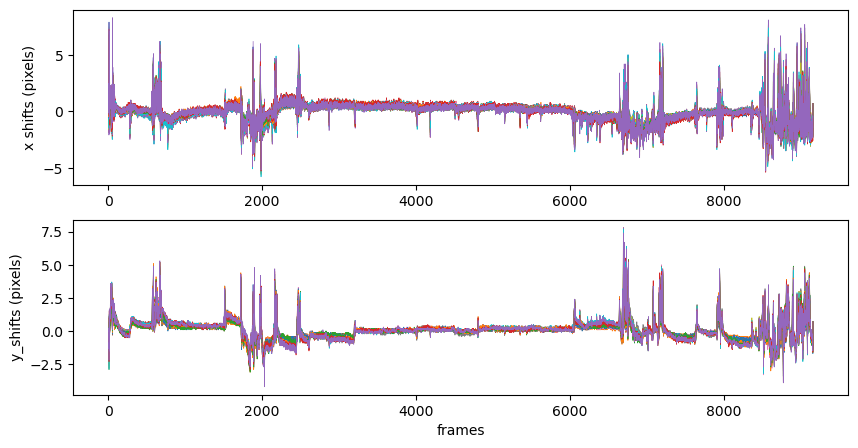

In [5]:
# %% visualize elastic shifts
plt.close()
plt.figure(figsize=(10, 5))
plt.subplot(2, 1, 1)
plt.plot(mc.x_shifts_els, linewidth=0.5)
plt.ylabel("x shifts (pixels)")
plt.subplot(2, 1, 2)
plt.plot(mc.y_shifts_els, linewidth=0.5)
plt.ylabel("y_shifts (pixels)")
plt.xlabel("frames")
# %% compute borders to exclude
bord_px_els = np.ceil(
    np.maximum(np.max(np.abs(mc.x_shifts_els)), np.max(np.abs(mc.y_shifts_els)))
).astype(int)

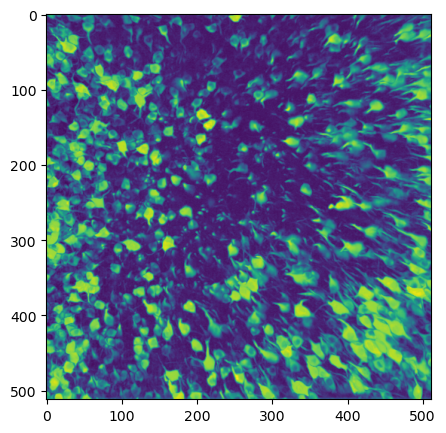

In [6]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 1, 1)

Text(0, 0.5, 'pixels')

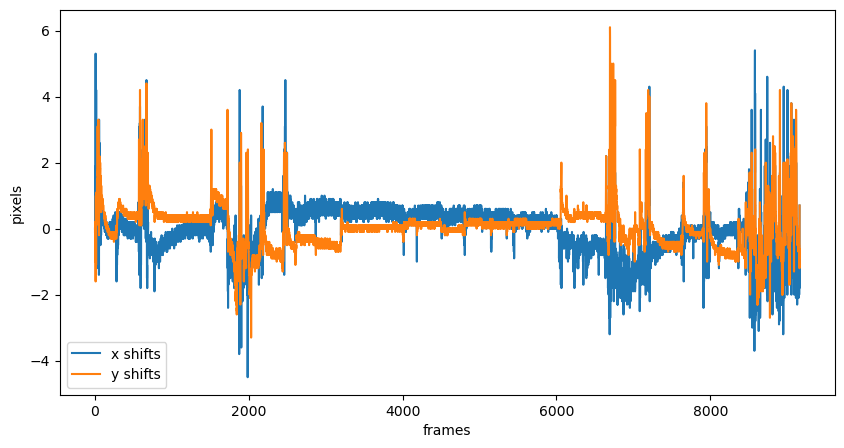

In [22]:
# %% plot rigid shifts
plt.close()
plt.figure(figsize=(10, 5))
plt.plot(mc.shifts_rig)
plt.legend(["x shifts", "y shifts"])
plt.xlabel("frames")
plt.ylabel("pixels")

In [6]:
import numpy as np

play_movies = True

# m_orig = cm.load_movie_chain(fname)
downsample_ratio = 0.2  # motion can be perceived better when downsampling in time
# m_orig.resize(1, 1, downsample_ratio)
# # Set play_movies to false if you want to disable play of movies, e.g. for remote-hosted Jupyter environments
# if play_movies:
#     m_orig.play(q_max=99.5, fr=30, magnification=2)  # play movie (press q to exit)

m_rig = cm.load(mc.mmap_file)
bord_px_rig = np.ceil(np.max(mc.shifts_rig)).astype(int)
m_rig.resize(1, 1, downsample_ratio)
if play_movies:
    m_rig.play(
        q_max=99.5, fr=15, magnification=2, bord_px=0 * bord_px_rig
    )  # press q to exit

100%|██████████| 1/1 [00:45<00:00, 45.39s/it]
qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in ""


In [ ]:
final_size = np.subtract(
    mc.total_template_els.shape, 2 * bord_px_els
)  # remove pixels in the boundaries
winsize = 100
swap_dim = False
resize_fact_flow = 0.2

tmpl_orig, correlations_orig, flows_orig, norms_orig, crispness_orig = (
    cm.motion_correction.compute_metrics_motion_correction(
        fname[0],
        final_size[0],
        final_size[1],
        swap_dim,
        winsize=winsize,
        play_flow=False,
        resize_fact_flow=resize_fact_flow,
    )
)

# tmpl_els, correlations_els, flows_els, norms_els, crispness_els = (
#     cm.motion_correction.compute_metrics_motion_correction(
#         mc.fname_tot_els[0],
#         final_size[0],
#         final_size[1],
#         swap_dim,
#         winsize=winsize,
#         play_flow=False,
#         resize_fact_flow=resize_fact_flow,
#     )
# )

In [ ]:
plt.figure(figsize=(20, 10))
plt.subplot(211)
plt.plot(correlations_orig)
plt.plot(correlations_els)
plt.legend(["Original", "PW-Rigid"])
plt.subplot(223)
plt.scatter(correlations_orig, correlations_els)
plt.xlabel("Original")
plt.ylabel("PW-Rigid")
plt.plot([0.3, 0.7], [0.3, 0.7], "r--")

/home/wollex/caiman_data/temp/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162_metrics.npz:
['flows', 'norms', 'correlations', 'smoothness', 'tmpl', 'smoothness_corr', 'img_corr']
	Norms: 7.681223e-05 +/- 3.306014e-05
	Smoothness: 10.560622 +/- 45.239432736106565
Loading data with base /home/wollex/caiman_data/temp/df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162


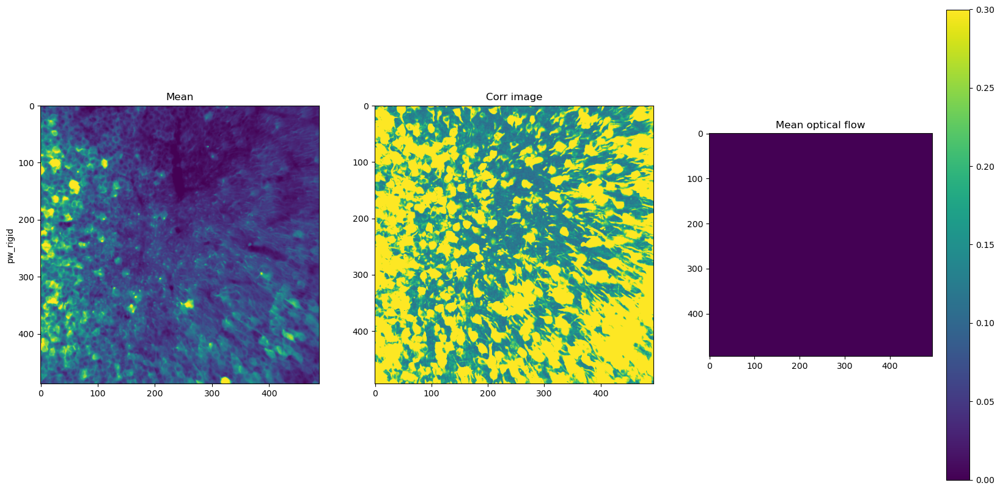

In [ ]:
# %% plot the results of Residual Optical Flow
# fls = [cm.paths.fname_derived_presuffix(mc.fname_tot_els[0], 'metrics', swapsuffix='npz'),
#     #    cm.paths.fname_derived_presuffix(mc.fname_tot_rig[0], 'metrics', swapsuffix='npz'),
#        cm.paths.fname_derived_presuffix(mc.fname[0],         'metrics', swapsuffix='npz'),
#       ]
import numpy as np

session_path = Path("../../../../data/KotaroData/493_copy/Session02/")

fls = [
    str(
        Path(os.environ["CAIMAN_TEMP"])
        / "df1cko#493_m1_hp_x16_x1.5_15v_71um_lres2t_els__d1_512_d2_512_d3_1_order_F_frames_9162_metrics.npz"
    )
]
n_mov = len(fls)

plt.figure(figsize=(20, 10))
for cnt, fl, metr in zip(range(len(fls)), fls, ["pw_rigid", "raw"]):
    with np.load(fl) as ld:
        print(f"{fl}:")
        print(list(ld.keys()))
        print(f"\tNorms: {str(np.mean(ld['norms']))} +/- {str(np.std(ld['norms']))}")
        print(f"\tSmoothness: {str(ld['smoothness'])} +/- {str(ld['smoothness_corr'])}")

        plt.subplot(len(fls), 3, 1 + 3 * cnt)
        plt.ylabel(metr)
        print(f"Loading data with base {fl[:-12]}")
        try:
            mean_img = np.mean(cm.load(fl[:-12] + ".mmap"), 0)[12:-12, 12:-12]
        except:
            try:
                mean_img = np.mean(cm.load(fl[:-12] + ".tif"), 0)[12:-12, 12:-12]
            except:
                mean_img = np.mean(cm.load(fl[:-12] + "hdf5"), 0)[12:-12, 12:-12]

        lq, hq = np.nanpercentile(mean_img, [0.5, 99.5])
        plt.imshow(mean_img, vmin=lq, vmax=hq)
        plt.title("Mean")
        plt.subplot(len(fls), 3, 3 * cnt + 2)
        plt.imshow(ld["img_corr"], vmin=0, vmax=0.35)
        plt.title("Corr image")
        plt.subplot(len(fls), 3, 3 * cnt + 3)
        flows = ld["flows"]
        plt.imshow(
            np.mean(np.sqrt(flows[:, :, :, 0] ** 2 + flows[:, :, :, 1] ** 2), 0),
            vmin=0,
            vmax=0.3,
        )
        plt.colorbar()
        plt.title("Mean optical flow")

In [ ]:
ld = np.load(fl)
ld.keys()

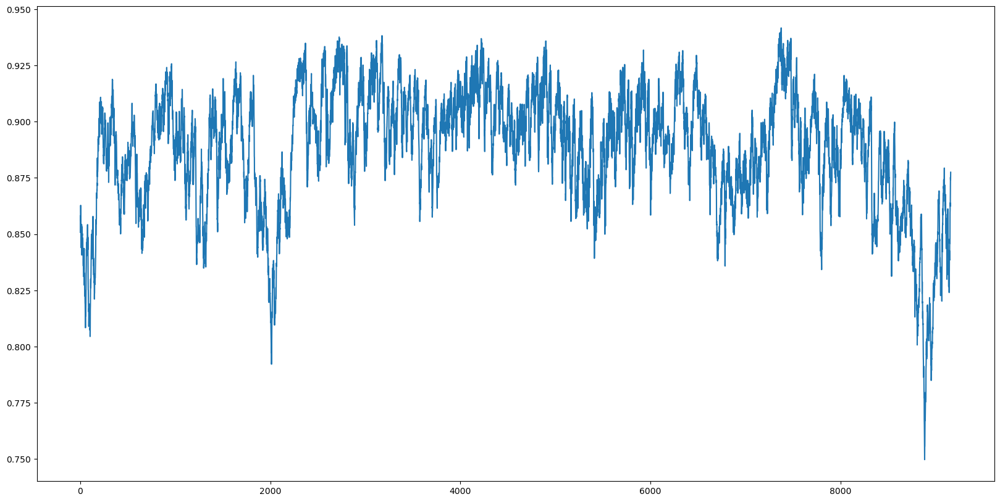

In [15]:
plt.figure(figsize=(20, 10))
# plt.subplot(211)
plt.plot(ld["correlations"])
# plt.plot(correlations_els)

In [ ]:
import cv2

cv2.destroyAllWindows()